# Project 2

Welcome to the second NLP1 project. The goal of the second tutorial was to get you familiar with using pre-trained embeddings and moving towards a compositional encoder for text classification.

Given the skills you have developed in the last week, you will now be applying them within the dataset and task you have chosen during Project 1. You will be applying hands-on the experiments you have already explored in the Tutorial 2, and taking a deeper dive: extending your experiments, trying different set ups, possibly considering different evaluation techniques and errors analyses, and tackling your own research questions. 


The week after the deadline, your TA will perform a short oral assessment of the skills and knowledge you acquired (make sure to check the official schedule for this), probing you to answer questions about what you learnt, about what you did and about why you did the things you did (as opposed to some reasonable alternatives) as well as pros and cons of your method, and so on. 

# Get to work!

1. Find a word embedding model that is appropriate for your dataset. Think about the language, the kind of text you are working with. Find evidence that your choice is a good one: 
    * Can you tokenize your texts in a way coherent with the definition of a token in the embedding model?
    * Does the model's vocabulary give enough coverage to the words in your texts? etc.
2. Explore what your chosen word embedding model captures. Some things you might consider: 
    * Is it good at representing interesting similarities (re to your choice of task)? J
    * Have you found task-specific evidence that it's better than some other reasonable alternative?
    * Do you know about limitations of this model?
    * Any limitations that you find particularly troubling for your task? 
3. Experiment with the embed-and-pool approach.  
    * What design choices have meaningful impact in classification performance (eg, embedding size, architecture design, optimisation parameters), if any?
    * Is this better than what you could achieve last week? In other words, did pretrained embeddings add to your design?
4. Experiment with a recurrent encoder (GRU or LSTM). 
    * What design choices have meaningful impact in classification performance, if any?
    * Did you investigate the impact of data size, embedding parameters (trained or not, fixed or trainable, etc)?
    * Did you struggle with over-fitting?
    * How far can this approach go? Are you able to improve meaningfully on embed-and-pool?
5. We make decisions under uncertainty all the time, are you gathering enough information to substantiate your choices? Various things can lead to small differences in results, and these differences are not always consistent. Here are some things to think about:
    * How did you structure you hyperparameter search?
    * Are you keeping an eye on experimental variance?
6. Experiment with error analysis and try to discover what characteristics of input texts are predictive of performance differences across major design choices. 
    * What analysis features did you come up with?
    * Which ones did you manage to test and how did that go?
    * What would you prioritise in the future in order to improve your systems?

Be mindful that you will be using your experiments to write up your final blog, so make sure your code is clean and neat!

If you are unsure about anything, ask your TA! They are always happy to help you! Happy coding! :)

# Tips

## Pretrained embedding models

We will post a list with some options for you. 

## Features for analysis

Features that you can interpret as an aspect of _complexity_ in light of your task's goals.

- length
- presence of rare/common words, including unknown words
- syntactic features (like parts-of-speech, syntactic complexity, syntactic voice, presence of negation, etc.)
- semantic features (eg, the average similarity of the text to training documents or some curated set of training documents, presence of words in certain semantic classes, etc.)
- task-specific features (eg, 
- model-specific features (eg, predicted label, probability assigned to predicted label, number of parameters or layers or some other model descriptor)

# Dataset and task

We continue with the English six-way emotion-classification task selected in Project 1. The data come from `dair-ai/emotion`, and the labels are sadness, joy, love, anger, fear, and surprise. The original train and validation splits form a pool of 18,000 texts. Before any vocabulary construction, tuning, or training, we carve out a class-balanced devtest set containing 100 texts per class (600 total). The devtest is reserved exclusively for error analysis: no model trains on it, and no hyperparameter, epoch, or model-selection choice is made using it. The remaining 17,400 texts are used for cross-validation. The original 2,000-text test set remains untouched until final evaluation.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

# The notebook is intended to run from the part2 directory.
root = Path.cwd().parent
sys.path.insert(0, str(root))

import part1

## Saving results locally

Everything this notebook produces is stored under `part2/results/` (which is git-ignored, so nothing is pushed to GitHub):

* `results/tables/*.csv`: every results table, written with `save_table`;
* `results/figures/*.png`: every figure, saved automatically whenever `plt.show()` is called (the file name is taken from the figure's title);
* `results/cache/*.pkl`: the outputs of expensive training runs, via `load_or_compute`. Re-running a training cell loads the stored results instead of retraining. The cache file name contains a hash of `DATA_VERSION`, `EXPERIMENT_VERSION` (the shared training protocol, defined below) and the experiment configuration, so changing the data split, the protocol or a setting automatically triggers a fresh run. Set `RERUN_EXPERIMENTS = True` to force retraining;
* trained models (`.pt` + `.json`, in folders named after `EXPERIMENT_VERSION`), the Optuna study (`results/optuna.db`, one study per `EXPERIMENT_VERSION`) and the LSTM score file are stored by the respective sections.

The cell also defines `corrected_resampled_ttest`, used for every cross-validation interval and paired comparison in this notebook.

In [ ]:
import hashlib
import json
import pickle
import re
import warnings

import matplotlib.pyplot as plt
from scipy import stats

RESULTS_DIR = Path("results")
TABLES_DIR = RESULTS_DIR / "tables"
FIGURES_DIR = RESULTS_DIR / "figures"
CACHE_DIR = RESULTS_DIR / "cache"
for directory in (TABLES_DIR, FIGURES_DIR, CACHE_DIR):
    directory.mkdir(parents=True, exist_ok=True)

RERUN_EXPERIMENTS = False   # True: ignore cached training results and retrain


def save_table(df, name, index=True):
    """Write a results table to results/tables/<name>.csv."""
    df.to_csv(TABLES_DIR / f"{name}.csv", index=index)


def _slug(text):
    return re.sub(r"[^a-z0-9]+", "_", text.lower()).strip("_")[:80] or "figure"


def _figure_name(fig):
    if fig._suptitle is not None and fig._suptitle.get_text():
        return _slug(fig._suptitle.get_text())
    for axis in fig.axes:
        if axis.get_title():
            return _slug(axis.get_title())
    return f"figure_{fig.number}"


if not getattr(plt.show, "_saves_figures", False):
    _original_show = plt.show

    def _show_and_save(*args, **kwargs):
        """plt.show() that first saves every open figure to results/figures/."""
        for number in plt.get_fignums():
            fig = plt.figure(number)
            fig.savefig(FIGURES_DIR / f"{_figure_name(fig)}.png", dpi=150, bbox_inches="tight")
        return _original_show(*args, **kwargs)

    _show_and_save._saves_figures = True
    plt.show = _show_and_save   # also covers helpers such as part1.analysis.plot_box_and_points


def load_or_compute(name, compute, key):
    """
    Return the cached result of `compute()` for this data split, training protocol
    (EXPERIMENT_VERSION) and experiment configuration (`key`), or run it and store the
    result in results/cache/<name>-<hash>.pkl.
    """
    cache_key = {
        "data_version": globals().get("DATA_VERSION"),
        "experiment_version": globals().get("EXPERIMENT_VERSION"),
        "key": key,
    }
    digest = hashlib.sha1(
        json.dumps(cache_key, sort_keys=True, default=str).encode()
    ).hexdigest()[:10]
    cache_path = CACHE_DIR / f"{name}-{digest}.pkl"
    if cache_path.exists() and not RERUN_EXPERIMENTS:
        print(f"Loaded cached results from {cache_path}")
        with open(cache_path, "rb") as cache_file:
            return pickle.load(cache_file)
    result = compute()
    with open(cache_path, "wb") as cache_file:
        pickle.dump(result, cache_file)
    print(f"Saved results to {cache_path}")
    return result


def corrected_resampled_ttest(values, num_folds, confidence=0.95):
    """
    Mean, confidence interval and two-sided p-value (against 0) for repeated k-fold
    cross-validation measurements, or for paired differences between two systems.

    Uses the corrected resampled t-test of Nadeau & Bengio (2003). The ordinary t-test treats
    the J = k x r measurements as independent, but cross-validation training sets overlap, so its
    intervals are too narrow. The correction replaces var/J by (1/J + n_test/n_train) * var,
    where n_test/n_train = 1/(k-1) for k-fold cross-validation.
    The p-value is only meaningful for paired differences.
    """
    values = np.asarray(values, dtype=float)
    n = len(values)
    mean = float(values.mean()) if n else np.nan
    if n < 2:
        return {"n": n, "mean": mean, "ci95_low": np.nan, "ci95_high": np.nan, "p_value": np.nan}
    se = float(np.sqrt((1 / n + 1 / (num_folds - 1)) * values.var(ddof=1)))
    t_crit = stats.t.ppf((1 + confidence) / 2, n - 1)
    if se > 0:
        p_value = float(2 * stats.t.sf(abs(mean / se), n - 1))
    else:
        p_value = 0.0 if mean != 0 else 1.0
    return {"n": n, "mean": mean, "ci95_low": mean - t_crit * se, "ci95_high": mean + t_crit * se, "p_value": p_value}

In [3]:
from datasets import concatenate_datasets, load_dataset
import pandas as pd

outcome_space = part1.clslib.NamedClasses(
    ['sadness', 'joy', 'love', 'anger', 'fear', 'surprise']
)

dataset = load_dataset("dair-ai/emotion", "split")
training_pool = concatenate_datasets(
    [dataset["train"], dataset["validation"]]
)
del dataset["validation"]

DEVTEST_PER_CLASS = 100
DEVTEST_SEED = 0
rng = np.random.default_rng(DEVTEST_SEED)
pool_labels = np.asarray(training_pool["label"])
devtest_indices = np.sort(np.concatenate([
    rng.choice(
        np.flatnonzero(pool_labels == label_id),
        size=DEVTEST_PER_CLASS,
        replace=False,
    )
    for label_id in range(len(outcome_space))
]))
train_indices = np.setdiff1d(
    np.arange(len(training_pool)), devtest_indices
)

dataset["devtest"] = training_pool.select(devtest_indices)
dataset["train"] = training_pool.select(train_indices)
DATA_VERSION = f"devtest{DEVTEST_PER_CLASS}pc-seed{DEVTEST_SEED}"

if "TABLES_DIR" not in globals():
    TABLES_DIR = Path("results") / "tables"
    TABLES_DIR.mkdir(parents=True, exist_ok=True)
pd.DataFrame({
    "pool_index": devtest_indices,
    "label": dataset["devtest"]["label"],
    "text": dataset["devtest"]["text"],
}).to_csv(
    TABLES_DIR / f"devtest_{DATA_VERSION}.csv", index=False
)

print(outcome_space)
print(dataset)
print(DATA_VERSION)

0: sadness, 1: joy, 2: love, 3: anger, 4: fear, 5: surprise
DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 17400
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 2000
    })
    devtest: Dataset({
        features: ['text', 'label'],
        num_rows: 600
    })
})
devtest100pc-seed0


## Training protocol

Every neural model in this notebook is trained under one protocol, defined once below, so that differences between systems are not caused by different training rules:

* **Epoch budget and early stopping.** Training runs for at most `MAX_EPOCHS` epochs and stops after `PATIENCE` epochs without improvement. The budget is deliberately generous: a short fixed budget would cut off slowly converging configurations (small learning rates, strong regularisation) and bias the hyperparameter search towards fast-learning settings.
* **Model selection.** The weights of the epoch with the best validation **macro-F1**, the primary metric, are kept. The Optuna search and `part2.experiment.train` use exactly the same rule, so a configuration is re-trained under the same rule that selected it.
* **Loss.** By default (`CLASS_WEIGHTED = True`) the loss is the inverse-frequency class-weighted negative log-likelihood, with weights computed from each fold's training partition only. Because this is a design choice, the embed-and-pool experiment also trains an otherwise identical model with an unweighted loss.
* **Vocabulary.** The embedding vocabulary contains the words of all unlabelled texts (training, devtest and test; see the embed-and-pool section). Only texts are used, never labels.

`EXPERIMENT_VERSION` summarises these settings. It is part of every cache key, the Optuna study name and the result folders, so results produced under a different protocol are never reused.

In [ ]:
MAX_EPOCHS = 30                 # upper bound; early stopping decides the actual number of epochs
PATIENCE = 4                    # epochs without improvement of the selection metric before stopping
SELECTION_METRIC = "macro_f1"   # the primary metric; the best epoch is kept by this metric everywhere
CLASS_WEIGHTED = True           # default loss; compared with an unweighted loss in the embed-and-pool experiment
VOCABULARY_SCOPE = "train+devtest+test"   # unlabelled texts whose words receive pretrained vectors

TRAINING_PROTOCOL = {
    "selection_metric": SELECTION_METRIC,
    "patience": PATIENCE,
    "class_weighted": CLASS_WEIGHTED,
}
EXPERIMENT_VERSION = (
    f"{DATA_VERSION}-max{MAX_EPOCHS}-pat{PATIENCE}-{SELECTION_METRIC}-"
    f"{'weighted' if CLASS_WEIGHTED else 'unweighted'}-vocab_{VOCABULARY_SCOPE.replace('+', '_')}"
)


def protocol_opt_kwargs(**overrides):
    """opt_kwargs for part2.experiment.train under the shared protocol (explicit overrides win)."""
    return {"num_epochs": MAX_EPOCHS, **TRAINING_PROTOCOL, **overrides}


print(f"Experiment version: {EXPERIMENT_VERSION}")

In [4]:
for index in [0, 2]:
    example = dataset["train"][index]
    print(f"Text: {example['text']}")
    print(f"Gold label (id): {example['label']}")
    print(f"Gold label (name): {outcome_space.name(example['label'])}\n")

Text: i didnt feel humiliated
Gold label (id): 0
Gold label (name): sadness

Text: im grabbing a minute to post i feel greedy wrong
Gold label (id): 3
Gold label (name): anger



## Class distributions

The class distribution is imbalanced: joy and sadness are the largest classes, while surprise is the smallest. This motivates reporting macro-F1 in addition to accuracy. By default, neural models are trained with an inverse-frequency class-weighted negative log-likelihood (see the training protocol), with weights recomputed from the training partition of each fold, so validation and test labels never influence the loss. This is treated as a design choice and tested against an unweighted loss in the embed-and-pool experiment.

---- train set (N=17400) ----
Sadness: 5116 examples (29.40%)
Joy: 5966 examples (34.29%)
Love: 1382 examples (7.94%)
Anger: 2334 examples (13.41%)
Fear: 2049 examples (11.78%)
Surprise: 553 examples (3.18%)


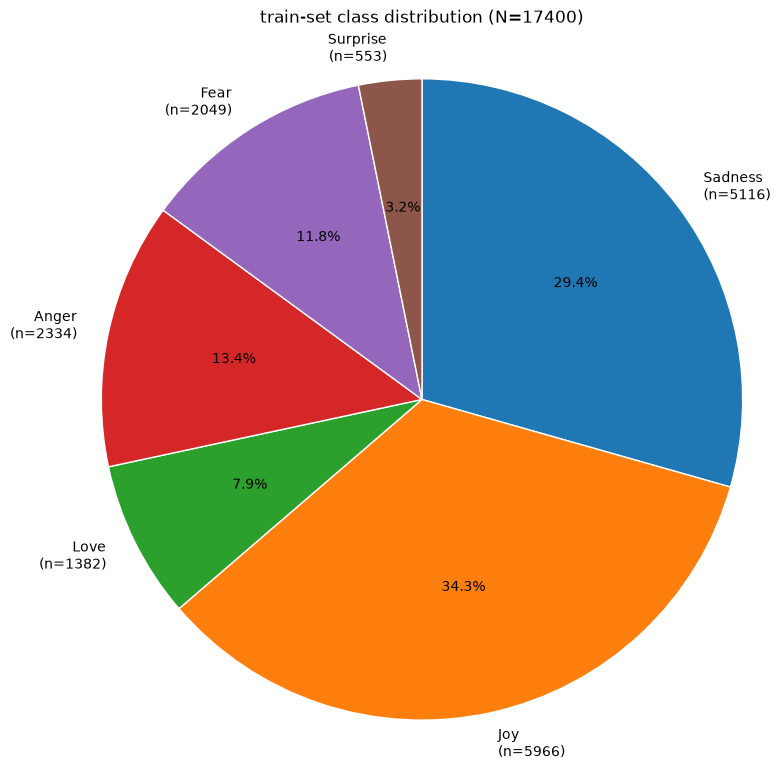

---- devtest set (N=600) ----
Sadness: 100 examples (16.67%)
Joy: 100 examples (16.67%)
Love: 100 examples (16.67%)
Anger: 100 examples (16.67%)
Fear: 100 examples (16.67%)
Surprise: 100 examples (16.67%)


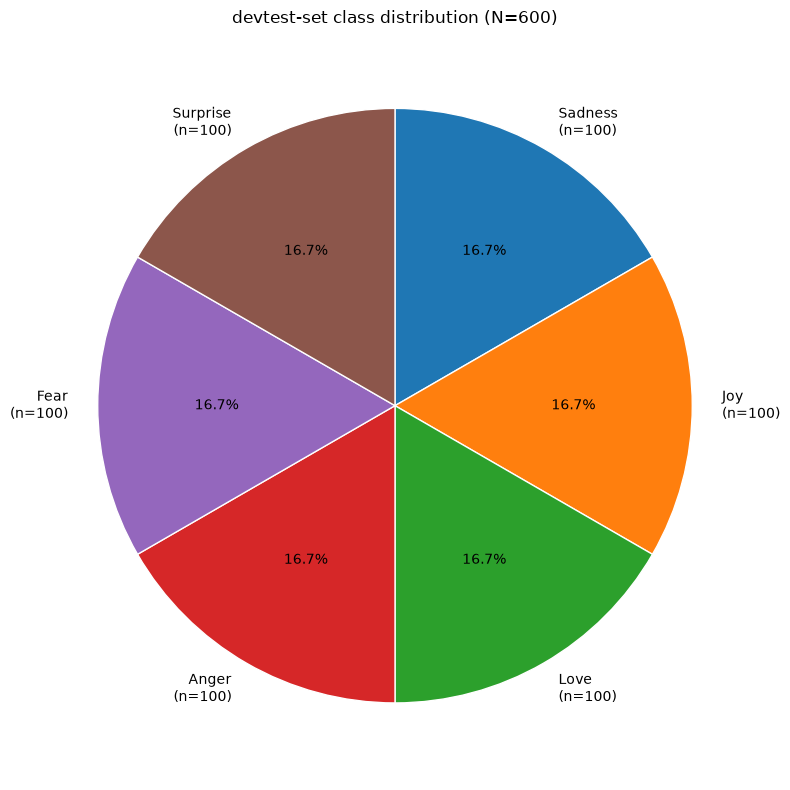

---- test set (N=2000) ----
Sadness: 581 examples (29.05%)
Joy: 695 examples (34.75%)
Love: 159 examples (7.95%)
Anger: 275 examples (13.75%)
Fear: 224 examples (11.20%)
Surprise: 66 examples (3.30%)


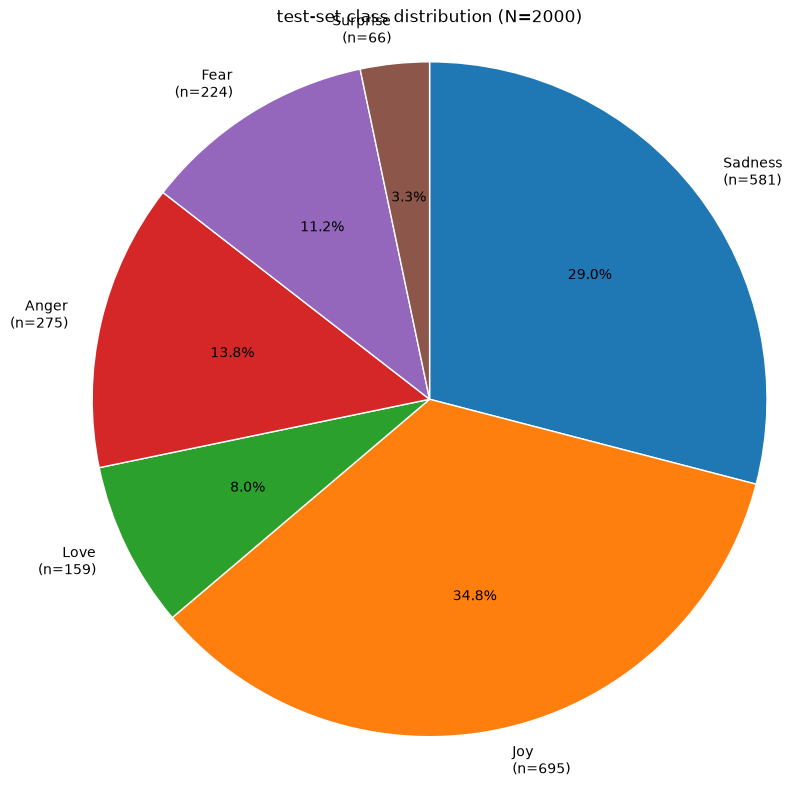

In [5]:
for split_name in ["train", "devtest", "test"]:
    labels = np.asarray(dataset[split_name]["label"])
    class_counts = np.bincount(labels, minlength=len(outcome_space))
    class_percentages = 100 * class_counts / labels.size

    print(f"---- {split_name} set (N={labels.size}) ----")
    for label_id, label_name in enumerate(outcome_space.names):
        print(
            f"{label_name.title()}: {class_counts[label_id]} examples "
            f"({class_percentages[label_id]:.2f}%)"
        )

    fig, ax = plt.subplots(figsize=(8, 8))
    ax.pie(
        class_counts,
        labels=[
            f"{name.title()}\n(n={count})"
            for name, count in zip(outcome_space.names, class_counts)
        ],
        autopct="%1.1f%%",
        startangle=90,
        counterclock=False,
        wedgeprops={"edgecolor": "white", "linewidth": 1},
    )
    ax.set_title(f"{split_name}-set class distribution (N={labels.size})")
    ax.axis("equal")
    plt.tight_layout()
    plt.show()

## Text-length distributions

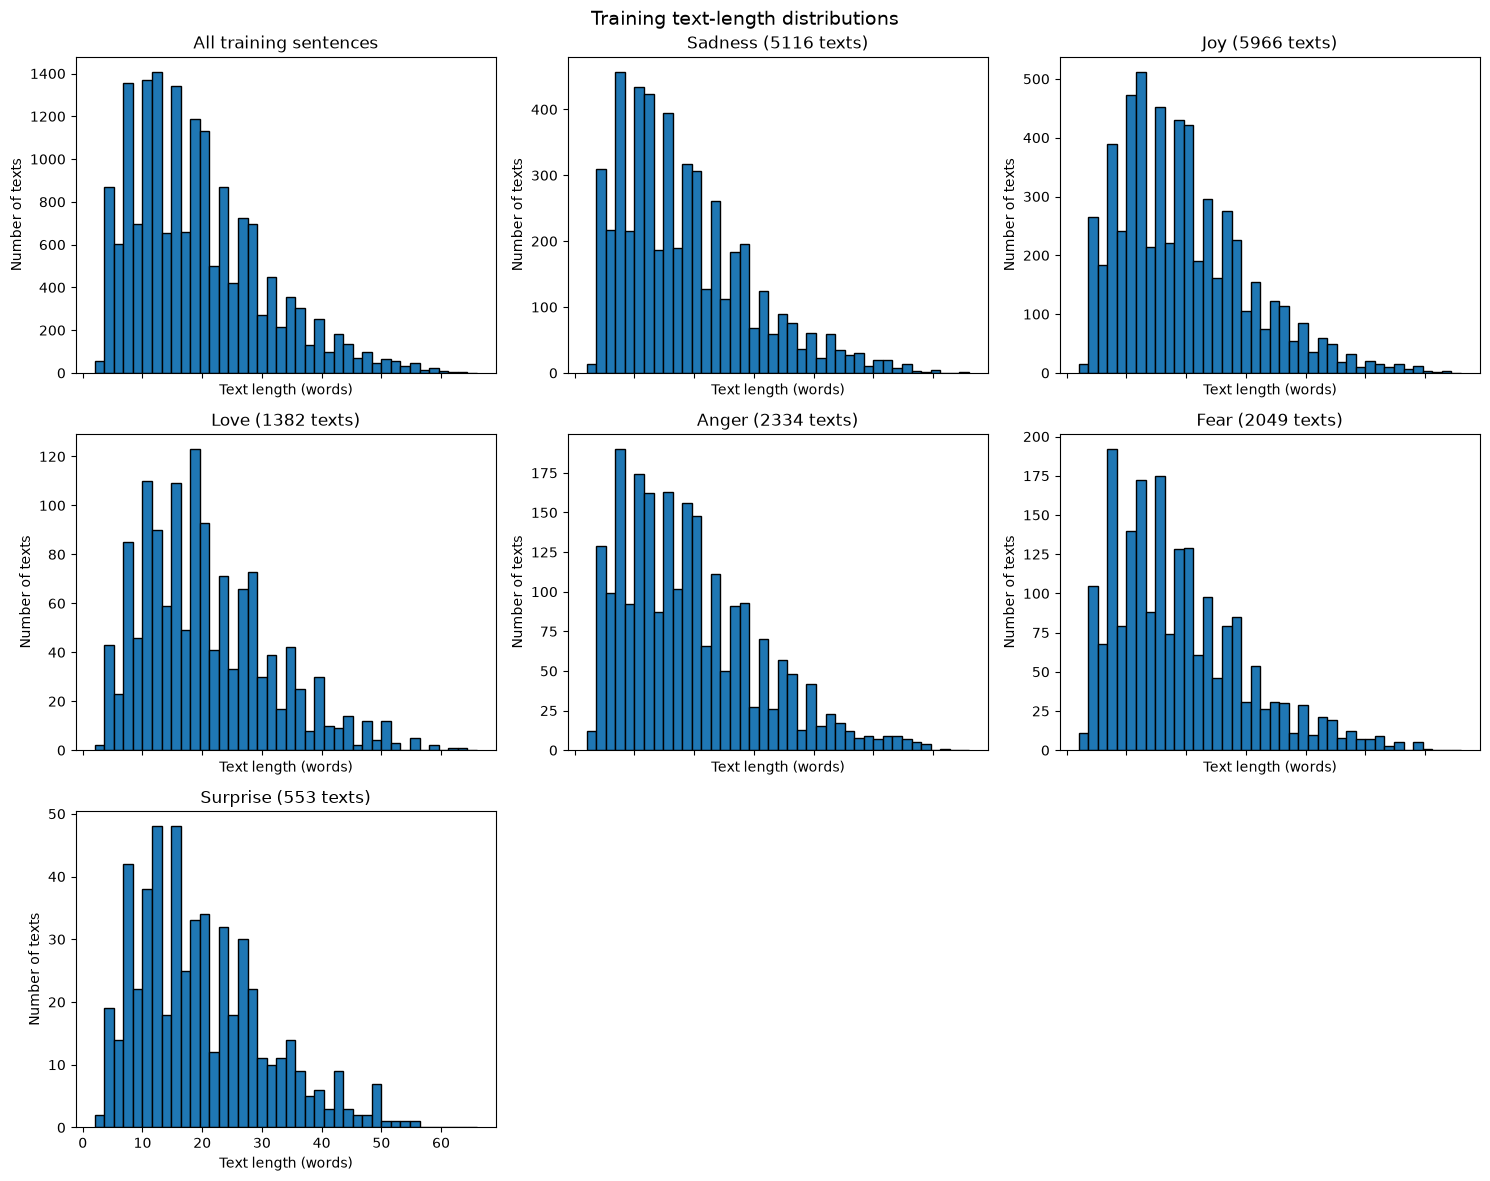

In [6]:
import math

train_texts = dataset["train"]["text"]
train_labels = np.asarray(dataset["train"]["label"])
text_lengths = np.asarray([len(text.split()) for text in train_texts])

num_plots = len(outcome_space) + 1
ncols = 3
nrows = math.ceil(num_plots / ncols)
fig, axes = plt.subplots(
    nrows=nrows, ncols=ncols, figsize=(5 * ncols, 4 * nrows), sharex=True
)
axes = np.atleast_1d(axes).flatten()
bin_edges = np.histogram_bin_edges(text_lengths, bins=40)

axes[0].hist(text_lengths, bins=bin_edges, edgecolor="black")
axes[0].set_title("All training sentences")
axes[0].set_xlabel("Text length (words)")
axes[0].set_ylabel("Number of texts")

for label_id, label_name in enumerate(outcome_space.names):
    class_lengths = text_lengths[train_labels == label_id]
    axis = axes[label_id + 1]
    axis.hist(class_lengths, bins=bin_edges, edgecolor="black")
    axis.set_title(f"{label_name.title()} ({len(class_lengths)} texts)")
    axis.set_xlabel("Text length (words)")
    axis.set_ylabel("Number of texts")

for axis in axes[num_plots:]:
    axis.set_visible(False)

fig.suptitle("Training text-length distributions", fontsize=14)
plt.tight_layout()
plt.show()

# Get to Work 1: Choosing a pretrained embedding model

Project 1 already established the dataset, a lowercase word-level tokenization procedure, and working loaders for GloVe embeddings. We transfer those components here as the starting point for selecting the Project 2 embedding model.

The dataset is English and consists of short, informal, first-person texts. We therefore consider two existing candidates: GloVe 6B, trained on Wikipedia and Gigaword, and GloVe Twitter 27B, trained on Twitter data. The Twitter model is intuitively better matched to forms such as `im` and `didnt`, but vocabulary coverage and task evidence still need to confirm that intuition.

## Word-level tokenization

Project 1 used a Hugging Face word-level tokenizer with a 1,000-word vocabulary cap. The next two cells keep it for reference, to show how much vocabulary that cap discarded. **All Project 2 models instead use `part2.clslib.BasicTokenizer`** (lowercase, punctuation removed, stopwords kept), whose word tokens are looked up directly in the embedding vocabulary. This produces word-like units compatible with the word-level entries used by GloVe, and the coverage analysis below uses the same tokenizer as the models.

In [7]:
from tokenizers import Tokenizer
from tokenizers.models import WordLevel
from tokenizers.normalizers import Lowercase
from tokenizers.pre_tokenizers import Whitespace
from tokenizers.trainers import WordLevelTrainer

vocab_size = 1000
min_frequency = 2
unk_token = "??"

tokenizer = Tokenizer(WordLevel(unk_token=unk_token))
tokenizer.normalizer = Lowercase()
tokenizer.pre_tokenizer = Whitespace()
trainer = WordLevelTrainer(
    vocab_size=vocab_size,
    min_frequency=min_frequency,
    special_tokens=[unk_token],
)
tokenizer.train_from_iterator(train_texts, trainer=trainer)

example_text = train_texts[0]
example_encoding = tokenizer.encode(example_text)
print("Original text:", example_text)
print("Tokens:", example_encoding.tokens)
print("Token IDs:", example_encoding.ids)

Original text: i didnt feel humiliated
Tokens: ['i', 'didnt', 'feel', 'humiliated']
Token IDs: [1, 141, 2, 652]


Unique normalized training tokens: 15,902
Tokens occurring at least 2 times: 7,766
Learned vocabulary size: 1,000
Eligible tokens excluded by the cap: 6,767


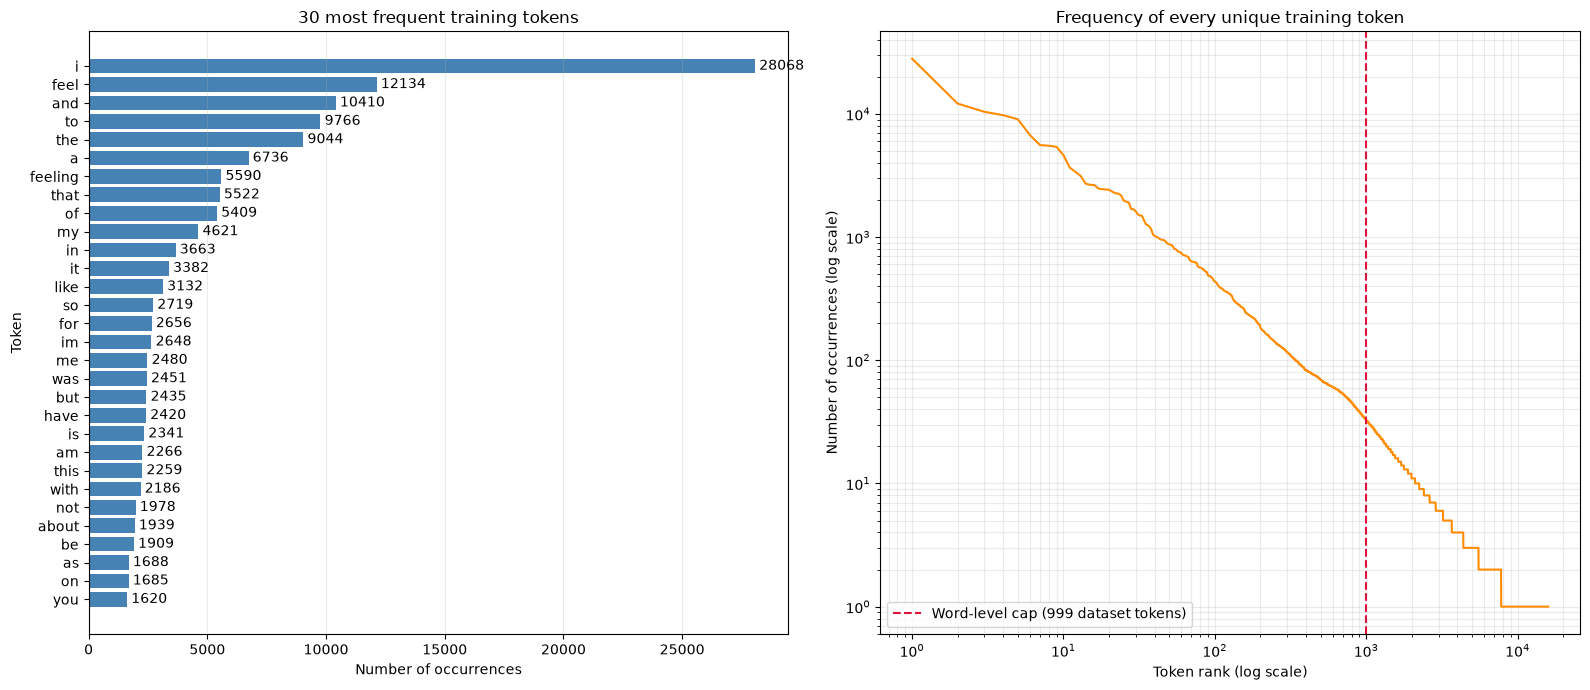

In [8]:
from collections import Counter

word_counts = Counter()
for document in train_texts:
    normalized = tokenizer.normalizer.normalize_str(document)
    pretokenized = tokenizer.pre_tokenizer.pre_tokenize_str(normalized)
    word_counts.update(token for token, _ in pretokenized)

num_unique_words = len(word_counts)
num_eligible_words = sum(
    frequency >= min_frequency for frequency in word_counts.values()
)
word_level_cap = vocab_size - 1
num_words_removed_by_cap = max(0, num_eligible_words - word_level_cap)

print(f"Unique normalized training tokens: {num_unique_words:,}")
print(f"Tokens occurring at least {min_frequency} times: {num_eligible_words:,}")
print(f"Learned vocabulary size: {len(tokenizer.get_vocab()):,}")
print(f"Eligible tokens excluded by the cap: {num_words_removed_by_cap:,}")

top_n = 30
top_words = word_counts.most_common(top_n)
words, counts = zip(*reversed(top_words))
all_counts = sorted(word_counts.values(), reverse=True)
ranks = range(1, len(all_counts) + 1)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
bars = axes[0].barh(words, counts, color="steelblue")
axes[0].bar_label(bars, padding=3, fmt="%d")
axes[0].set_title(f"{top_n} most frequent training tokens")
axes[0].set_xlabel("Number of occurrences")
axes[0].set_ylabel("Token")
axes[0].grid(axis="x", alpha=0.25)

axes[1].loglog(ranks, all_counts, color="darkorange")
axes[1].axvline(
    word_level_cap, color="crimson", linestyle="--",
    label=f"Word-level cap ({word_level_cap:,} dataset tokens)",
)
axes[1].set_title("Frequency of every unique training token")
axes[1].set_xlabel("Token rank (log scale)")
axes[1].set_ylabel("Number of occurrences (log scale)")
axes[1].grid(alpha=0.25, which="both")
axes[1].legend()
plt.tight_layout()
plt.show()

## Existing GloVe candidates from Project 1

Project 1 established working loaders for both Twitter GloVe and GloVe 6B. For a controlled comparison in Project 2, `shared_glove_dim` selects **one common dimensionality for both models**, so embedding dimensionality is held constant while the training corpus changes. Set it to 50, 100, or 200 and rerun the notebook. The paths below reuse the downloaded files from the `part1/glove` directory.

In [ ]:
glove_root = root / "part1" / "glove"

# Change this one value to use the same dimensionality for both models.
# The dimensions available for both GloVe collections are 50, 100, and 200.
shared_glove_dim = 50
common_glove_dimensions = {50, 100, 200}
if shared_glove_dim not in common_glove_dimensions:
    raise ValueError(
        f"shared_glove_dim must be one of {sorted(common_glove_dimensions)}, "
        f"not {shared_glove_dim}."
    )

embedding_candidates = {
    "glove_twitter": (
        glove_root / "glove.twitter.27B"
        / f"glove.twitter.27B.{shared_glove_dim}d.txt",
        shared_glove_dim,
    ),
    "glove_6B": (
        glove_root / f"glove.6B.{shared_glove_dim}d.txt",
        shared_glove_dim,
    ),
}

for name, (path, dimension) in embedding_candidates.items():
    if not path.exists():
        raise FileNotFoundError(f"Missing embedding file: {path}")
    print(f"{name}: dimension={dimension}, path={path}")

## Count the dataset words

In [ ]:
from collections import Counter

import part2

# The same word tokenization as every Project 2 model: lowercase, punctuation removed,
# stopwords kept (negation and intensifiers are informative for emotion).
surface_tokenizer = part2.clslib.BasicTokenizer(
    lowercase=True,
    remove_punct=True,
    remove_stopwords=False,
    language="english",
    vocab=None,
)


def corpus_word_counts(texts):
    counts = Counter()
    for text in texts:
        counts.update(surface_tokenizer.tokens(text))
    return counts


split_word_counts = {
    split: corpus_word_counts(dataset[split]["text"])
    for split in ["train", "devtest", "test"]
}
train_word_counts = split_word_counts["train"]

for split, counts in split_word_counts.items():
    print(f"{split}: {len(counts):,} word types, {sum(counts.values()):,} word tokens")

## Embedding-vocabulary coverage

We measure coverage with the models' own tokenizer, before any vocabulary cap, and **on every split**: coverage of the training texts determines what the classifier can learn from, while coverage of the devtest and test texts determines what it sees at evaluation time.

We report **type coverage** (the proportion of distinct dataset words present in the embedding vocabulary), **token coverage** (the proportion of all word occurrences covered), and document-level coverage. Token coverage is especially important because rare misspellings can lower type coverage without affecting many texts. We also count evaluation words that never occur in training but do have a pretrained vector: these are exactly the words for which a pretrained embedding can help a classifier that never saw them.

In [ ]:
import pandas as pd


def find_covered_words(embedding_path, required_words):
    """Return the required words that occur in a pretrained embedding vocabulary."""
    required_words = set(required_words)
    covered_words = set()

    with open(embedding_path, encoding="utf8") as embedding_file:
        for line in embedding_file:
            word = line.split(maxsplit=1)[0]
            if word in required_words:
                covered_words.add(word)

    return covered_words


def coverage_statistics(texts, word_counts, covered_words):
    covered_words = set(covered_words) & set(word_counts)
    total_tokens = sum(word_counts.values())
    covered_tokens = sum(
        frequency
        for word, frequency in word_counts.items()
        if word in covered_words
    )

    document_coverages = []
    for text in texts:
        tokens = surface_tokenizer.tokens(text)
        if tokens:
            document_coverages.append(
                sum(token in covered_words for token in tokens) / len(tokens)
            )

    document_coverages = np.asarray(document_coverages)
    return {
        "type_coverage": len(covered_words) / len(word_counts),
        "token_coverage": covered_tokens / total_tokens,
        "mean_document_coverage": document_coverages.mean(),
        "fully_covered_documents": np.mean(document_coverages == 1.0),
        "documents_below_80pct": np.mean(document_coverages < 0.8),
        "covered_types": len(covered_words),
        "total_types": len(word_counts),
        "covered_tokens": covered_tokens,
        "total_tokens": total_tokens,
    }

In [ ]:
all_dataset_words = set().union(*split_word_counts.values())
covered_words_by_model = {
    model_name: find_covered_words(embedding_path, all_dataset_words)
    for model_name, (embedding_path, _) in embedding_candidates.items()
}

coverage_rows = []
for model_name, covered_words in covered_words_by_model.items():
    for split, counts in split_word_counts.items():
        coverage_rows.append({
            "model": model_name,
            "split": split,
            **coverage_statistics(dataset[split]["text"], counts, covered_words),
        })

coverage_df = pd.DataFrame(coverage_rows).set_index(["model", "split"])
save_table(coverage_df, "coverage")
display(coverage_df.style.format({
    "type_coverage": "{:.2%}",
    "token_coverage": "{:.2%}",
    "mean_document_coverage": "{:.2%}",
    "fully_covered_documents": "{:.2%}",
    "documents_below_80pct": "{:.2%}",
    "covered_types": "{:,}",
    "total_types": "{:,}",
    "covered_tokens": "{:,}",
    "total_tokens": "{:,}",
}))

# Evaluation words never seen in training: a pretrained vector is their only representation.
unseen_rows = []
for split in ("devtest", "test"):
    unseen_types = set(split_word_counts[split]) - set(train_word_counts)
    unseen_tokens = sum(split_word_counts[split][word] for word in unseen_types)
    for model_name, covered_words in covered_words_by_model.items():
        unseen_rows.append({
            "split": split,
            "model": model_name,
            "types_unseen_in_training": len(unseen_types),
            "tokens_unseen_in_training": unseen_tokens,
            "unseen_types_with_pretrained_vector": len(unseen_types & covered_words),
        })
unseen_words_df = pd.DataFrame(unseen_rows)
save_table(unseen_words_df, "evaluation_words_unseen_in_training", index=False)
display(unseen_words_df)

## Frequent words without embeddings

Aggregate percentages are not sufficient by themselves. We also inspect frequent unknown words to determine whether the missing vocabulary consists mainly of harmless rare forms or task-relevant emotion expressions.

In [13]:
top_n_unknowns = 30
unknown_rows = []

for model_name, covered_words in covered_words_by_model.items():
    most_common_unknowns = [
        (word, frequency)
        for word, frequency in train_word_counts.most_common()
        if word not in covered_words
    ][:top_n_unknowns]

    for rank, (word, frequency) in enumerate(most_common_unknowns, start=1):
        unknown_rows.append({
            "model": model_name,
            "rank": rank,
            "word": word,
            "frequency": frequency,
        })

unknown_words_df = pd.DataFrame(unknown_rows)
save_table(unknown_words_df, "frequent_unknown_words", index=False)
display(
    unknown_words_df.pivot(
        index="rank", columns="model", values=["word", "frequency"]
    )
)

word                 frequency              
model         glove_6B   glove_twitter  glove_6B glove_twitter
rank                                                          
1                 href       pagetitle       180             7
2             shouldnt         twinges        28             3
3                hadnt          siwons        18             2
4                youve        percieve        15             2
5                 hadn            vbac        10             2
6             nofollow       undesired        10             2
7                theyd       clearboth         7             2
8            pagetitle       amvassago         7             2
9               werent          adomen         7             2
10              theyve            unza         6             2
11           everyones       complainy         5             2
12              theyll      regimented         5             2
13         everythings        custodes         4             2
14           permalink          aryiku         4             2
15                itll          gunong         3             2
16             anyones      creaminess         3             2
17             wouldve    unworthiness         3             2
18             couldve        haircute         3             2
19                 idk  constructivism         3             2
20     allowfullscreen          prided         3             2
21               wifes         plusone         3             2
22                maxs           yomis         2             2
23              siwons        bellmont         2             2
24            thrifted         lenghth         2             1
25            societys        jacynthe         2             1
26              incase         gerling         2             1
27           vunerable  supportiveness         2             1
28              hahaha         dwelled         2             1
29            percieve         dannika         2             1
30               ahaha           wryly         2             1

## Coverage conclusion

Both pretrained vocabularies cover the dataset well, measured with the models' own tokenizer. On the training texts, Twitter GloVe covers **99.69% of token occurrences** and **93.79% of distinct word types**; GloVe 6B covers **99.58%** and **93.28%**. The lower type coverage is not concerning because most uncovered types are rare: mean document coverage is 99.71% for Twitter GloVe and 99.56% for GloVe 6B, and only 0.05% (Twitter) versus 0.16% (6B) of training documents have less than 80% coverage. The evaluation splits look the same: test token coverage is 99.70% (Twitter) versus 99.57% (6B), and Twitter GloVe fully covers 94.75% of test documents versus 92.90% for GloVe 6B.

The two models differ in *which* words they miss. Twitter GloVe's most frequent unknown training word occurs only seven times, whereas GloVe 6B misses frequent web-related forms (`href`, `nofollow`) and informal contractions without apostrophes such as `shouldnt`, `hadnt` and `youve`, which are typical of this dataset.

Coverage of words that never occur in training matters too: 914 word types in the test set (971 occurrences) are unseen in training, and 800 of them have a Twitter-GloVe vector (799 for GloVe 6B). With a pretrained vocabulary these words keep a meaningful representation at test time; a classifier trained from scratch would treat all of them as unknown. The embedding tables below therefore keep vectors for the words of all splits.

We therefore choose **GloVe Twitter 27B** as the leading embedding model. Its vocabulary coverage is slightly better, and its Twitter training domain is closer to the short, informal, first-person texts in the emotion dataset. Coverage alone does not show that its vectors encode emotions better, so the following analyses still examine semantic structure and downstream validation performance.

Finally, the Project 1 vocabulary cap is not used in Project 2. Restricting tokenization to 999 dataset words would convert 6,767 frequent-enough words to `??` even though GloVe has vectors for most of them. The Project 2 tokenizer instead maps words against the embedding vocabulary and reserves the unknown token for genuinely uncovered words.

# Emotion structure in the embedding spaces

We now test whether the embedding spaces capture similarities relevant to the six-way emotion task. Rather than selecting convenient example words by hand, we reuse the five most informative words for every class from the final Project 1 token-indicator logistic classifier. These were obtained by averaging each class's logistic-regression coefficients across the five folds and selecting the largest positive coefficients.

For each embedding model we L2-normalise the 30 word vectors and compute the cosine similarity of every word pair. Entry $(i,j)$ of the class-similarity matrix is the **average cosine similarity over all word pairs with one word from class $i$ and one from class $j$**:

* **Off-diagonal** entries average the $5 \times 5 = 25$ cross-class pairs and measure how close two classes are in the embedding space.
* **Diagonal** entries average the $\binom{5}{2} = 10$ pairs of *different* words within a class (a word's similarity with itself is always 1 and is excluded). They measure how **cohesive** a class is, so the diagonal is no longer fixed at 1.

We average pairwise similarities rather than comparing averaged class vectors ("prototypes") because averaging vectors first smooths out differences between the individual words, which makes classes look more similar and more cohesive than their words really are. The pairwise version keeps that spread, and comparing each class's diagonal entry with its off-diagonal entries shows whether a class is tighter internally than it is close to the other classes, a rough indication of how separable its cue words are.

In [14]:
# Top positive-weight words copied from the final analysis in Project 1.
informative_words = {
    "sadness": ["lethargic", "unwelcome", "troubled", "groggy", "melancholy"],
    "joy": ["superior", "divine", "sincere", "valued", "convinced"],
    "love": ["sympathetic", "nostalgic", "horny", "naughty", "fond"],
    "anger": ["offended", "resentful", "irritable", "rushed", "dangerous"],
    "fear": ["pressured", "shaken", "terrified", "vulnerable", "apprehensive"],
    "surprise": ["curious", "impressed", "amazed", "dazed", "surprised"],
}

informative_words

{'sadness': ['lethargic', 'unwelcome', 'troubled', 'groggy', 'melancholy'],
 'joy': ['superior', 'divine', 'sincere', 'valued', 'convinced'],
 'love': ['sympathetic', 'nostalgic', 'horny', 'naughty', 'fond'],
 'anger': ['offended', 'resentful', 'irritable', 'rushed', 'dangerous'],
 'fear': ['pressured', 'shaken', 'terrified', 'vulnerable', 'apprehensive'],
 'surprise': ['curious', 'impressed', 'amazed', 'dazed', 'surprised']}

In [15]:
def load_selected_vectors(embedding_path, embedding_dim, required_words):
    """Load only the requested vectors instead of the complete embedding table."""
    required_words = set(required_words)
    selected_vectors = {}

    with open(embedding_path, encoding="utf8") as embedding_file:
        for line in embedding_file:
            parts = line.rstrip().split()
            if len(parts) != embedding_dim + 1:
                continue

            word = parts[0].lower()
            if word in required_words:
                selected_vectors[word] = np.asarray(parts[1:], dtype=np.float32)

    return selected_vectors


all_informative_words = {
    word
    for words in informative_words.values()
    for word in words
}

selected_vectors_by_model = {}
for model_name, (embedding_path, embedding_dim) in embedding_candidates.items():
    vectors = load_selected_vectors(
        embedding_path, embedding_dim, all_informative_words
    )
    selected_vectors_by_model[model_name] = vectors
    missing = sorted(all_informative_words.difference(vectors))
    print(
        f"{model_name}: found {len(vectors)}/{len(all_informative_words)} words; "
        f"missing={missing}"
    )

glove_twitter: found 30/30 words; missing=[]
glove_6B: found 30/30 words; missing=[]


For a fair comparison, both models use the same words for every class. If either embedding vocabulary lacks a word, that word is excluded from both models rather than allowing the matrices to use different evidence.

In [ ]:
import seaborn as sns

class_names = list(informative_words)
common_words = set.intersection(
    *(set(vectors) for vectors in selected_vectors_by_model.values())
)

words_used_by_class = {
    class_name: [
        word for word in informative_words[class_name]
        if word in common_words
    ]
    for class_name in class_names
}

if any(len(words) < 2 for words in words_used_by_class.values()):
    raise ValueError("Every class needs at least two words shared by both embedding models.")


def average_pairwise_similarity_matrix(vectors, words_by_class, class_names):
    """
    Entry (i, j) is the mean cosine similarity over all word pairs with one word from class i
    and one from class j. On the diagonal, pairs of a word with itself are excluded.
    """
    normalized = {
        class_name: np.stack([vectors[word] for word in words_by_class[class_name]])
        for class_name in class_names
    }
    normalized = {
        class_name: matrix / np.clip(np.linalg.norm(matrix, axis=1, keepdims=True), 1e-12, None)
        for class_name, matrix in normalized.items()
    }
    similarity = np.zeros((len(class_names), len(class_names)))
    for i, class_i in enumerate(class_names):
        for j, class_j in enumerate(class_names):
            pair_cosines = normalized[class_i] @ normalized[class_j].T
            if i == j:
                off_diagonal = ~np.eye(len(pair_cosines), dtype=bool)
                similarity[i, j] = pair_cosines[off_diagonal].mean()
            else:
                similarity[i, j] = pair_cosines.mean()
    return similarity


# (kept under the name gram_matrices because later cells read it)
gram_matrices = {
    model_name: average_pairwise_similarity_matrix(vectors, words_used_by_class, class_names)
    for model_name, vectors in selected_vectors_by_model.items()
}

for model_name, similarity in gram_matrices.items():
    save_table(
        pd.DataFrame(similarity, index=class_names, columns=class_names),
        f"class_similarity_matrix_{model_name}_{shared_glove_dim}d",
    )

display(pd.DataFrame(words_used_by_class).T.rename(columns=lambda i: f"word_{i + 1}"))

# One colour scale for both models, so the heatmaps are directly comparable.
color_min = min(0.0, min(matrix.min() for matrix in gram_matrices.values()))
color_max = max(matrix.max() for matrix in gram_matrices.values())

fig, axes = plt.subplots(1, 2, figsize=(16, 6), constrained_layout=True)
plot_titles = {
    "glove_twitter": f"Twitter GloVe 27B ({shared_glove_dim}d)",
    "glove_6B": f"Wikipedia/Gigaword GloVe 6B ({shared_glove_dim}d)",
}

for axis, model_name in zip(axes, embedding_candidates):
    similarity_df = pd.DataFrame(
        gram_matrices[model_name], index=class_names, columns=class_names
    )
    sns.heatmap(
        similarity_df,
        annot=True,
        fmt=".2f",
        cmap="viridis",
        vmin=color_min,
        vmax=color_max,
        square=True,
        ax=axis,
        cbar_kws={"label": "Mean pairwise cosine similarity"},
    )
    axis.set_title(plot_titles.get(model_name, model_name))
    axis.set_xlabel("Emotion class")
    axis.set_ylabel("Emotion class")

fig.suptitle(
    "Average pairwise cosine similarity of class cue words (diagonal: within class)",
    fontsize=15,
)
plt.show()

In [ ]:
# Within-class cohesion versus similarity to the other classes.
cohesion_rows = []
for model_name, similarity in gram_matrices.items():
    for i, class_name in enumerate(class_names):
        between = np.delete(similarity[i], i)
        cohesion_rows.append({
            "model": model_name,
            "class": class_name,
            "within_class": similarity[i, i],
            "mean_between_class": between.mean(),
            "max_between_class": between.max(),
            "closest_other_class": class_names[[j for j in range(len(class_names)) if j != i][int(between.argmax())]],
            "within_minus_mean_between": similarity[i, i] - between.mean(),
        })
cohesion_df = pd.DataFrame(cohesion_rows)
save_table(cohesion_df, f"class_cohesion_{shared_glove_dim}d", index=False)
print("Within-class cohesion versus between-class similarity:")
display(cohesion_df.round(3))

# Summarize the strongest and weakest between-class relationships.
relationship_rows = []
for model_name, similarity in gram_matrices.items():
    for i in range(len(class_names)):
        for j in range(i + 1, len(class_names)):
            relationship_rows.append({
                "model": model_name,
                "class_a": class_names[i],
                "class_b": class_names[j],
                "mean_pairwise_cosine": similarity[i, j],
            })

relationship_df = pd.DataFrame(relationship_rows)
save_table(relationship_df, f"class_relationships_{shared_glove_dim}d", index=False)
for model_name in embedding_candidates:
    model_relationships = relationship_df[
        relationship_df["model"] == model_name
    ].sort_values("mean_pairwise_cosine", ascending=False)

    print(f"\n{model_name}")
    print("Most similar class pairs:")
    display(model_relationships.head(3))
    print("Least similar class pairs:")
    display(model_relationships.tail(3).sort_values("mean_pairwise_cosine"))

## Interpretation

Both embedding models contain all 30 cue words, so every matrix entry is based on the same words. The values below are for `shared_glove_dim = 50`.

**Similarities are moderate, not near 1.** Average pairwise cosines lie between 0.17 and 0.63. Individual cue words of the same emotion are far less similar to each other than averaged class vectors would suggest, which is why we compare word pairs rather than prototypes.

**Cohesion differs strongly between classes** (cohesion table, `within_minus_mean_between`):

* In **Twitter GloVe**, sadness (within 0.55, +0.19 above its mean similarity to other classes) and surprise (0.63, +0.22) are clearly cohesive. **Anger (−0.01) and love (−0.02) are not**: their cue words are, on average, no more similar to each other than to other classes' words, and joy is only slightly more cohesive (+0.04).
* In **GloVe 6B**, all similarities are lower. Surprise (+0.21), joy (+0.12), fear (+0.11) and love (+0.08) are cohesive, sadness barely (+0.02), and **anger again is not (−0.05)**.
* Averaged over the six classes, the margin is almost identical for the two models (+0.078 for Twitter, +0.081 for 6B). On these words, neither space separates the emotions better; Twitter GloVe mainly places all words closer together. Raw values should therefore not be compared across models, only the within-versus-between pattern. This is consistent with the two models performing similarly when their embeddings are frozen; check this against the frozen embed-and-pool results below.

**Between-class structure is plausible and consistent across models.** **Anger–fear** is among the most similar pairs in both models (0.47 Twitter, 0.43 6B), and in Twitter GloVe sadness–fear is just as close (0.46). These are negative emotions that occur in related situations. **Sadness–joy is the least similar pair in both models** (0.27 and 0.17), matching the intuitive contrast. For anger, the closest other class is fear in both models, and its words are as close to fear's words as to each other. This predicts that a model relying on (pooled) word vectors will confuse **anger with fear**; the error analysis can check this in the confusion matrices.

**Caveats.** The analysis is a diagnostic, not a classification score. Each entry averages only 10 (within) or 25 (between) word pairs, so small differences are noisy. The cue words were selected for their predictive weights in Project 1, not as dictionary definitions: the anger list contains `rushed` and `dangerous`, and the love list mixes `sympathetic`, `nostalgic`, `horny` and `naughty`, which partly explains why these classes look less cohesive. Finally, GloVe learns from co-occurrence, so contrasting emotions can be similar when they appear in comparable contexts. Downstream cross-validation remains necessary to decide which representation works better.

# Embed-and-pool experiment

Following the Part 2 tutorial, an embed-and-pool encoder maps each token ID to its pretrained vector and averages or sums the vectors along the sequence dimension. The resulting fixed-dimensional document vector is passed to a two-hidden-layer softmax regressor. This is a continuous bag-of-words model: it uses dense word representations but discards word order.

We conduct a controlled comparison with one shared embedding dimensionality and identical data folds, tokenizer, classifier architecture, and optimization settings. The systems test: (1) Twitter versus Wikipedia/Gigaword pretraining, (2) mean versus sum pooling, (3) frozen versus trainable pretrained embeddings, (4) pretrained versus randomly initialized trainable embeddings, and (5) a class-weighted versus an unweighted training loss. The random baseline is important because it tests whether pretrained vectors add information beyond the architecture and vocabulary.

## Embedding tables and vocabulary

The original GloVe files are very large, so we keep only the vectors of words that occur in our data. The vocabulary is built from the **unlabelled texts of all splits** (training, devtest and test). This uses no labels and does not change what the classifier learns from: words that occur only in evaluation texts receive no gradient and keep their pretrained vector. It matters because it is exactly what pretrained embeddings are for: a word that never occurs in training still has a meaningful representation at evaluation time. With a training-only vocabulary, such words would all collapse to `<unk>`, which would understate the benefit of pretrained (and especially frozen) embeddings and bias the comparison with random embeddings.

Each model receives a zero padding vector and an unknown vector equal to the mean of its retained pretrained vectors, matching the strategy in `part2.clslib.PretrainedEmbeddings`. The random baseline uses the same vocabulary, so it differs only in the vector values.

In [ ]:
import copy
import random

import torch
from sklearn.metrics import f1_score

import part2


class CorpusEmbeddings:
    """Minimal embedding-model interface expected by part2.experiment."""

    def __init__(self, vocab, vectors, pad_token="<pad>", unk_token="<unk>"):
        self.vocab = vocab
        self.vectors = vectors
        self.pad_token = pad_token
        self.unk_token = unk_token


def load_corpus_embeddings(embedding_path, embedding_dim, required_words):
    pad_token, unk_token = "<pad>", "<unk>"
    vocab = part2.clslib.Vocabulary(
        [pad_token, unk_token], default=unk_token
    )
    vectors = [
        np.zeros(embedding_dim, dtype=np.float32),
        np.zeros(embedding_dim, dtype=np.float32),
    ]
    required_words = set(required_words)

    with open(embedding_path, encoding="utf8") as embedding_file:
        for line in embedding_file:
            parts = line.rstrip().split()
            if len(parts) != embedding_dim + 1:
                continue
            word = parts[0].lower()
            if word in required_words and word not in vocab:
                vocab.add(word)
                vectors.append(np.asarray(parts[1:], dtype=np.float32))

    vectors = np.stack(vectors)
    vectors[vocab.default_index] = vectors[2:].mean(axis=0)
    vocab.freeze()
    return CorpusEmbeddings(vocab, vectors, pad_token, unk_token)


# Vocabulary: every word in the unlabelled texts of all splits (see the markdown above).
# `surface_tokenizer` and `split_word_counts` are defined in the coverage section.
corpus_words = set().union(*split_word_counts.values())

corpus_embedding_models = {
    name: load_corpus_embeddings(path, dimension, corpus_words)
    for name, (path, dimension) in embedding_candidates.items()
}

for name, model in corpus_embedding_models.items():
    print(
        f"{name}: vectors={model.vectors.shape}, "
        f"vocabulary words with a pretrained vector={len(model.vocab) - 2:,}/{len(corpus_words):,}"
    )

In [19]:
def make_random_embedding_model(reference_model, seed=0):
    """Random table with the same vocabulary, shape and scale as a reference."""
    rng = np.random.default_rng(seed)
    scale = reference_model.vectors[2:].std()
    vectors = rng.normal(
        loc=0.0, scale=scale, size=reference_model.vectors.shape
    ).astype(np.float32)
    vectors[reference_model.vocab.index(reference_model.pad_token)] = 0.0
    return CorpusEmbeddings(
        reference_model.vocab,
        vectors,
        reference_model.pad_token,
        reference_model.unk_token,
    )

random_embedding_model = make_random_embedding_model(
    corpus_embedding_models["glove_twitter"], seed=0
)

## Experimental design

Every system is trained on the same 3-fold splits for three split seeds (0, 1, 2), giving **9 paired measurements per system**. The seed also sets weight initialisation and minibatch order. All systems share the tokenizer, the classifier architecture, the optimiser settings and the training protocol (early stopping on validation macro-F1, at most `MAX_EPOCHS` epochs), and differ only in the factor under study. We report accuracy and macro-F1; macro-F1 is primary because the emotion labels are imbalanced.

Cross-validation measurements are not independent: the training sets of different folds overlap. Intervals and p-values for means and paired differences therefore use the corrected resampled t-test (Nadeau & Bengio, 2003), which widens the ordinary t-interval to account for this overlap.

These settings are untuned defaults shared by all systems. The comparison is therefore fair between systems, but a system that would profit more from tuning could be under-estimated; only the selected configuration is tuned afterwards.

In [ ]:
from collections import OrderedDict

embed_pool_seeds = [0, 1, 2]
embed_pool_num_folds = 3
embed_pool_device = (
    "mps" if torch.backends.mps.is_available() else "cpu"
)
embed_pool_results_folder = Path("results") / "embed-and-pool" / EXPERIMENT_VERSION
embed_pool_results_folder.mkdir(parents=True, exist_ok=True)

embed_pool_splits = [
    part1.experiment.cross_validation_split(
        list(zip(dataset["train"]["text"], dataset["train"]["label"])),
        k=embed_pool_num_folds,
        seed=seed,
    )
    for seed in embed_pool_seeds
]

embed_pool_configs = OrderedDict({
    "twitter_mean_frozen": {
        "embedding_model": corpus_embedding_models["glove_twitter"],
        "average_pool": True,
        "freeze_embeddings": True,
    },
    "twitter_sum_frozen": {
        "embedding_model": corpus_embedding_models["glove_twitter"],
        "average_pool": False,
        "freeze_embeddings": True,
    },
    "glove6B_mean_frozen": {
        "embedding_model": corpus_embedding_models["glove_6B"],
        "average_pool": True,
        "freeze_embeddings": True,
    },
    "twitter_mean_trainable": {
        "embedding_model": corpus_embedding_models["glove_twitter"],
        "average_pool": True,
        "freeze_embeddings": False,
    },
    "glove6B_mean_trainable": {
        "embedding_model": corpus_embedding_models["glove_6B"],
        "average_pool": True,
        "freeze_embeddings": False,
    },
    "random_mean_trainable": {
        "embedding_model": random_embedding_model,
        "average_pool": True,
        "freeze_embeddings": False,
    },
    # identical to twitter_mean_trainable except for the loss: tests the class-weighting choice
    "twitter_mean_trainable_unweighted": {
        "embedding_model": corpus_embedding_models["glove_twitter"],
        "average_pool": True,
        "freeze_embeddings": False,
        "class_weighted": False,
    },
})

common_regressor_kwargs = {
    "hidden_size1": 64,
    "hidden_size2": 64,
    "dropout": 0.2,
}
common_optimizer_kwargs = {          # the epoch budget and stopping rule come from the protocol
    "learning_rate": 1e-3,
    "weight_decay": 1e-4,
    "batch_size": 128,
}

print(f"Device: {embed_pool_device}")
print(f"Systems: {list(embed_pool_configs)}")
print(
    f"Measurements per system: "
    f"{len(embed_pool_seeds) * embed_pool_num_folds}"
)

In [ ]:
def run_embed_pool_experiment():
    embed_pool_classifiers = OrderedDict()

    for system_name, config in embed_pool_configs.items():
        print(f"\n===== {system_name} =====")
        embed_pool_classifiers[system_name] = []

        embedding_model = config["embedding_model"]
        model_tokenizer = part2.clslib.BasicTokenizer(
            lowercase=True,
            remove_punct=True,
            remove_stopwords=False,
            language="english",
            vocab=embedding_model.vocab,
        )

        for run, seed in enumerate(embed_pool_seeds):
            # Deterministic initialization and minibatch order for reproducibility.
            experiment_seed = seed
            random.seed(experiment_seed)
            np.random.seed(experiment_seed)
            torch.manual_seed(experiment_seed)

            run_folder = (
                embed_pool_results_folder / system_name / f"seed-{seed}"
            )
            run_result = part2.experiment.cross_validation(
                outcome_space=outcome_space,
                data_splits=embed_pool_splits[run],
                tokenizer=model_tokenizer,
                emb_model=embedding_model,
                enc_type="embed-and-pool",
                enc_kwargs={
                    "average_pool": config["average_pool"],
                    "freeze_embeddings": config["freeze_embeddings"],
                },
                regressor_kwargs=dict(common_regressor_kwargs),
                opt_kwargs=protocol_opt_kwargs(
                    **common_optimizer_kwargs,
                    class_weighted=config.get("class_weighted", CLASS_WEIGHTED),
                ),
                device=embed_pool_device,
                save_to=run_folder,
            )

            run_result["macro_f1_scores"] = OrderedDict()
            for fold, predictions in run_result["predictions"].items():
                gold = [
                    label
                    for _, label in embed_pool_splits[run][fold]["validation"]
                ]
                run_result["macro_f1_scores"][fold] = f1_score(
                    gold, predictions, average="macro", zero_division=0
                )

            embed_pool_classifiers[system_name].append(run_result)
    return embed_pool_classifiers


embed_pool_classifiers = load_or_compute(
    "embed_pool_classifiers",
    run_embed_pool_experiment,
    key={
        "systems": {
            name: {k: v for k, v in config.items() if k != "embedding_model"}
            for name, config in embed_pool_configs.items()
        },
        "regressor": common_regressor_kwargs,
        "optimizer": common_optimizer_kwargs,
        "seeds": embed_pool_seeds,
        "folds": embed_pool_num_folds,
        "glove_dim": shared_glove_dim,
        "protocol": TRAINING_PROTOCOL,
        "max_epochs": MAX_EPOCHS,
    },
)
embed_pool_results_version = EXPERIMENT_VERSION   # lets later sections check these results are current

## Embed-and-pool results

Each point below is one validation-fold measurement: 3 split seeds x 3 folds = 9 per system.

accuracy                  macro_f1                
                            mean       std count      mean       std count
model                                                                     
twitter_mean_trainable  0.805115  0.003291     3  0.753043  0.007567     3
glove6B_mean_trainable  0.793678  0.002107     3  0.735632  0.008281     3
random_mean_trainable   0.747414  0.017779     3  0.701387  0.020884     3
glove6B_mean_frozen     0.398678  0.014756     3  0.342062  0.002844     3
twitter_mean_frozen     0.377989  0.005620     3  0.341931  0.005774     3

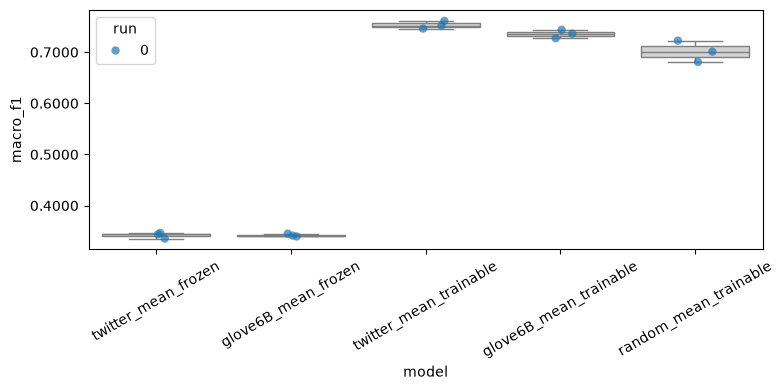

In [22]:
embed_pool_results_df = part1.analysis.make_data_frame(
    embed_pool_classifiers
)
embed_pool_summary = (
    embed_pool_results_df
    .groupby("model")[["accuracy", "macro_f1"]]
    .agg(["mean", "std", "count"])
    .sort_values(("macro_f1", "mean"), ascending=False)
)
save_table(embed_pool_results_df, "embed_pool_scores", index=False)
save_table(embed_pool_summary, "embed_pool_summary")
display(embed_pool_summary)
part1.analysis.plot_box_and_points(
    embed_pool_results_df, metric="macro_f1"
)

In [ ]:
# Paired fold differences for the controlled research questions.
paired_questions = [
    ("Twitter vs GloVe 6B (frozen mean)",
     "twitter_mean_frozen", "glove6B_mean_frozen"),
    ("Mean vs sum pooling (frozen Twitter)",
     "twitter_mean_frozen", "twitter_sum_frozen"),
    ("Fine-tuned vs frozen Twitter",
     "twitter_mean_trainable", "twitter_mean_frozen"),
    ("Twitter vs GloVe 6B (trainable mean)",
     "twitter_mean_trainable", "glove6B_mean_trainable"),
    ("Pretrained vs random trainable embeddings",
     "twitter_mean_trainable", "random_mean_trainable"),
    ("Class-weighted vs unweighted loss (trainable Twitter)",
     "twitter_mean_trainable", "twitter_mean_trainable_unweighted"),
]

comparison_rows = []
skipped_comparisons = []
expected_pairs = len(embed_pool_seeds) * embed_pool_num_folds
for question, system_a, system_b in paired_questions:
    paired_scores = (
        embed_pool_results_df[embed_pool_results_df["model"].isin([system_a, system_b])]
        .pivot_table(index=["run", "fold"], columns="model", values="macro_f1")
    )
    if system_a not in paired_scores or system_b not in paired_scores:
        skipped_comparisons.append({"question": question, "A": system_a, "B": system_b,
                                    "status": "skipped: system missing"})
        continue
    paired_scores = paired_scores[[system_a, system_b]].dropna()
    if len(paired_scores) != expected_pairs:
        skipped_comparisons.append({"question": question, "A": system_a, "B": system_b,
                                    "status": f"skipped: {len(paired_scores)}/{expected_pairs} paired measurements"})
        continue

    differences = (paired_scores[system_a] - paired_scores[system_b]).to_numpy()
    test = corrected_resampled_ttest(differences, embed_pool_num_folds)
    comparison_rows.append({
        "question": question, "A": system_a, "B": system_b, "n": test["n"],
        "mean_macro_f1_A_minus_B": test["mean"],
        "ci95_low": test["ci95_low"], "ci95_high": test["ci95_high"],
        "corrected_p": test["p_value"],
        "A_wins": int(np.sum(differences > 0)),
        "B_wins": int(np.sum(differences < 0)),
    })

paired_embed_pool_comparisons = pd.DataFrame(comparison_rows)
if not paired_embed_pool_comparisons.empty:
    paired_embed_pool_comparisons = paired_embed_pool_comparisons.set_index("question")
    save_table(paired_embed_pool_comparisons, "embed_pool_paired_comparisons")
    display(paired_embed_pool_comparisons.round(4))

if skipped_comparisons:
    print("Skipped comparisons:")
    display(pd.DataFrame(skipped_comparisons).set_index("question"))

# Did early stopping, rather than the epoch budget, end training?
epoch_rows = [
    {"system": system_name, "run": run, "fold": fold,
     "best_epoch": run_result["best_epochs"][fold], "epochs_run": run_result["epochs_run"][fold]}
    for system_name, runs in embed_pool_classifiers.items()
    for run, run_result in enumerate(runs)
    for fold in run_result["best_epochs"]
]
embed_pool_epochs_df = pd.DataFrame(epoch_rows)
save_table(embed_pool_epochs_df, "embed_pool_best_epochs", index=False)
display(embed_pool_epochs_df.groupby("system")[["best_epoch", "epochs_run"]].agg(["median", "max"]))
capped = embed_pool_epochs_df[embed_pool_epochs_df["best_epoch"] >= MAX_EPOCHS]
if len(capped):
    warnings.warn(f"{len(capped)} runs kept their last allowed epoch; consider a larger MAX_EPOCHS.")

## Embed-and-pool interpretation

*To be written after running the experiment above (the numbers depend on the current protocol and data split).* Use the paired comparison table: a difference whose corrected 95% interval excludes zero, with a consistent win count, is evidence of a real effect; otherwise report it as inconclusive. Points to address:

* **Trainable vs frozen:** how large is the gain from updating the embeddings?
* **Twitter vs GloVe 6B:** is there a difference when the embeddings are frozen, when they are trainable, or both? A difference only for trainable embeddings would suggest that Twitter GloVe is a better *starting point for fine-tuning* rather than a better fixed representation.
* **Pretrained vs random:** does pretraining add information beyond the architecture and vocabulary?
* **Mean vs sum pooling** and **class-weighted vs unweighted loss:** do these choices matter? The class-weighted loss should trade some accuracy for macro-F1; check both metrics.
* **Epochs:** confirm in the epoch table that early stopping, not the epoch budget, ended training.

# Hyperparameter optimization for Twitter GloVe

The preliminary comparison selected trainable Twitter GloVe with mean pooling. We now optimize the remaining design choices without touching the held-out test set.

**Search protocol.**
* **Objective:** every trial is scored by its *mean macro-F1 over all three folds* of the tuning split (split seed 0), not on a single fold, which makes the objective less noisy and harder to overfit.
* **Training rule:** the same as everywhere else in the notebook: at most `MAX_EPOCHS` epochs, early stopping after `PATIENCE` epochs without improvement, and the epoch with the best validation macro-F1 is kept. The generous budget avoids cutting off slowly converging configurations, which would bias the search towards high learning rates.
* **Budget:** 60 trials (TPE sampler with 10 random start-up trials) and median pruning after each fold, so clearly weak configurations stop after one or two folds.
* **Noise control:** within a fold, every trial uses the same initialisation and minibatch seed (common random numbers), so trials differ only by their hyperparameters; the seed differs between folds, so a trial's score averages over three initialisations rather than optimising for a single lucky one.
* **Search space:** embedding dimensionality (50/100/200), widths of both hidden layers (16–128), dropout (0–0.5), learning rate (2e-4–1e-2, log scale), weight decay (1e-6–1e-3, log scale) and batch size (64/128/256).
* **Persistence:** the study is stored in `results/optuna.db` under a name containing `EXPERIMENT_VERSION`, so results survive kernel restarts and re-running the cell resumes the search instead of starting over.

Mean pooling and trainable Twitter embeddings remain fixed because the earlier controlled experiment selected them. Only this family is tuned; the other embedding types were compared with shared untuned settings.

In [ ]:
import gc

import optuna
import torch.nn as nn
from torch.utils.data import DataLoader

OPTUNA_SEED = 17
OPTUNA_TRIALS = 60               # total trials in the study (the search resumes up to this number)
OPTUNA_TIMEOUT_SECONDS = 3600    # safety cap for one call of study.optimize
OPTUNA_MAX_EPOCHS = MAX_EPOCHS   # same budget and stopping rule as every other training run
OPTUNA_PATIENCE = PATIENCE
OPTUNA_STUDY_NAME = f"embed-pool-twitter-3fold-{EXPERIMENT_VERSION}"
OPTUNA_STORAGE = "sqlite:///results/optuna.db"
twitter_embedding_dimensions = [50, 100, 200]

# Tuning uses the split-seed-0 folds; the confirmation later uses different split seeds.
tuning_splits = embed_pool_splits[0]
tuning_folds = list(tuning_splits.keys())

# Load each corpus-restricted table once; trials reuse these arrays.
twitter_embeddings_by_dim = {}
for dimension in twitter_embedding_dimensions:
    if dimension == shared_glove_dim:
        model = corpus_embedding_models["glove_twitter"]
    else:
        path = (
            glove_root / "glove.twitter.27B"
            / f"glove.twitter.27B.{dimension}d.txt"
        )
        model = load_corpus_embeddings(path, dimension, corpus_words)
    twitter_embeddings_by_dim[dimension] = model
    print(f"Twitter GloVe {dimension}d: {model.vectors.shape}")


def make_tokenizer(embedding_model):
    return part2.clslib.BasicTokenizer(
        lowercase=True, remove_punct=True, remove_stopwords=False,
        language="english", vocab=embedding_model.vocab,
    )


# Cache tokenized datasets per (dimension, fold) so trials never re-tokenize.
tuning_data_by_dim = {}
for dimension, embedding_model in twitter_embeddings_by_dim.items():
    tuning_tokenizer = make_tokenizer(embedding_model)
    pad_id = embedding_model.vocab.index(embedding_model.pad_token)
    tuning_data_by_dim[dimension] = {}
    for fold in tuning_folds:
        fold_data = {}
        for part in ("training", "validation"):
            pairs = tuning_splits[fold][part]
            fold_data[part] = part2.experiment.LabelledCorpus(
                [tuning_tokenizer.ids(text) for text, _ in pairs],
                [int(label) for _, label in pairs],
            )
        fold_data["pad_id"] = pad_id
        tuning_data_by_dim[dimension][fold] = fold_data

print(
    f"Tuning split: {len(tuning_folds)} folds of "
    f"{len(tuning_splits[0]['training']):,} training and "
    f"{len(tuning_splits[0]['validation']):,} validation examples"
)

In [ ]:
def train_fold(params, fold_data, seed=OPTUNA_SEED):
    """Train one embed-and-pool model on one fold; return its best validation macro-F1 and epoch."""
    pad_id = fold_data["pad_id"]
    embedding_model = twitter_embeddings_by_dim[params["embedding_dim"]]

    # Common random numbers: within a fold every trial uses the same seed, so trials differ only by
    # hyperparameters; the caller passes a different seed for each fold.
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    generator = torch.Generator().manual_seed(seed)

    collate = lambda batch: part2.experiment.collate_labelled_texts(batch, padding_value=pad_id)
    train_loader = DataLoader(
        fold_data["training"], batch_size=params["batch_size"], shuffle=True,
        generator=generator, collate_fn=collate,
    )
    validation_loader = DataLoader(
        fold_data["validation"], batch_size=params["batch_size"], shuffle=False,
        collate_fn=collate,
    )

    encoder = part2.clslib.EmbedAndPoolEncoder(
        embedding_matrix=torch.tensor(embedding_model.vectors, dtype=torch.float32),
        average_pool=True, freeze_embeddings=False, padding_idx=pad_id,
    )
    model = part2.clslib.SoftmaxRegressor(
        hidden_size1=params["hidden_size1"], hidden_size2=params["hidden_size2"],
        num_classes=len(outcome_space), encoder=encoder, dropout=params["dropout"],
    ).to(embed_pool_device)
    if CLASS_WEIGHTED:
        criterion = part2.experiment.class_weighted_nll_loss(
            fold_data["training"].y, len(outcome_space), embed_pool_device
        )
    else:
        criterion = nn.NLLLoss()
    optimizer = torch.optim.AdamW(
        model.parameters(), lr=params["learning_rate"], weight_decay=params["weight_decay"]
    )

    best_macro_f1, best_epoch, epochs_without_improvement = -np.inf, -1, 0
    try:
        for epoch in range(OPTUNA_MAX_EPOCHS):
            part2.experiment.training_one_epoch(
                model, train_loader, optimizer, criterion, embed_pool_device
            )
            validation_metrics = part2.experiment.evaluate(
                model, validation_loader, criterion, embed_pool_device
            )
            predictions = np.asarray(
                [p for batch in validation_metrics["predictions"] for p in batch]
            )
            labels = np.asarray(
                [y for batch in validation_metrics["labels"] for y in batch]
            )
            macro_f1 = f1_score(labels, predictions, average="macro", zero_division=0)

            if macro_f1 > best_macro_f1 + 1e-4:
                best_macro_f1, best_epoch, epochs_without_improvement = macro_f1, epoch, 0
            else:
                epochs_without_improvement += 1
            if epochs_without_improvement >= OPTUNA_PATIENCE:
                break
        return float(best_macro_f1), best_epoch + 1
    finally:
        del model, encoder, optimizer, train_loader, validation_loader
        gc.collect()
        if torch.backends.mps.is_available():
            torch.mps.empty_cache()


def optuna_embed_pool_objective(trial):
    params = {
        "embedding_dim": trial.suggest_categorical("embedding_dim", [50, 100, 200]),
        "hidden_size1": trial.suggest_categorical("hidden_size1", [16, 32, 64, 128]),
        "hidden_size2": trial.suggest_categorical("hidden_size2", [16, 32, 64, 128]),
        "dropout": trial.suggest_float("dropout", 0.0, 0.5, step=0.1),
        "learning_rate": trial.suggest_float("learning_rate", 2e-4, 1e-2, log=True),
        "weight_decay": trial.suggest_float("weight_decay", 1e-6, 1e-3, log=True),
        "batch_size": trial.suggest_categorical("batch_size", [64, 128, 256]),
    }

    fold_scores, fold_epochs = [], []
    for step, fold in enumerate(tuning_folds):
        score, epoch = train_fold(
            params, tuning_data_by_dim[params["embedding_dim"]][fold], seed=OPTUNA_SEED + step
        )
        fold_scores.append(score)
        fold_epochs.append(epoch)
        # Report the running mean after each fold so the pruner can stop weak trials early.
        trial.report(float(np.mean(fold_scores)), step=step)
        if trial.should_prune():
            raise optuna.TrialPruned()

    trial.set_user_attr("fold_macro_f1", [round(s, 4) for s in fold_scores])
    trial.set_user_attr("fold_macro_f1_std", float(np.std(fold_scores, ddof=1)))
    trial.set_user_attr("best_epochs", fold_epochs)
    return float(np.mean(fold_scores))

In [ ]:
optuna.logging.set_verbosity(optuna.logging.WARNING)
Path("results").mkdir(exist_ok=True)

study = optuna.create_study(
    study_name=OPTUNA_STUDY_NAME,
    storage=OPTUNA_STORAGE,
    load_if_exists=True,   # re-running this cell resumes the stored study
    direction="maximize",
    sampler=optuna.samplers.TPESampler(
        seed=OPTUNA_SEED, n_startup_trials=10, multivariate=True
    ),
    pruner=optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=0),
)

finished_states = (optuna.trial.TrialState.COMPLETE, optuna.trial.TrialState.PRUNED)
remaining_trials = OPTUNA_TRIALS - len(study.get_trials(states=finished_states))
if remaining_trials > 0:
    study.optimize(
        optuna_embed_pool_objective,
        n_trials=remaining_trials,
        timeout=OPTUNA_TIMEOUT_SECONDS,
        n_jobs=1,
        gc_after_trial=True,
        show_progress_bar=True,
    )

n_complete = len(study.get_trials(states=(optuna.trial.TrialState.COMPLETE,)))
n_pruned = len(study.get_trials(states=(optuna.trial.TrialState.PRUNED,)))
print(f"Trials: {n_complete} complete, {n_pruned} pruned")
print(f"Best 3-fold mean macro-F1 (tuning split): {study.best_value:.4f}")
print(f"Per-fold macro-F1: {study.best_trial.user_attrs.get('fold_macro_f1')}")
print(f"Best epochs per fold: {study.best_trial.user_attrs.get('best_epochs')}")
complete_trials = study.get_trials(states=(optuna.trial.TrialState.COMPLETE,))
capped_trials = sum(
    any(epoch >= OPTUNA_MAX_EPOCHS for epoch in trial.user_attrs.get("best_epochs", []))
    for trial in complete_trials
)
print(f"Completed trials whose best epoch hit the {OPTUNA_MAX_EPOCHS}-epoch cap in some fold: "
      f"{capped_trials}/{len(complete_trials)}")
print("Best parameters:")
best_params_df = pd.Series(study.best_params, name="value").to_frame()
save_table(best_params_df, "optuna_best_params")
display(best_params_df)
# The best parameters can be reloaded later without re-running the search:
# optuna.load_study(study_name=OPTUNA_STUDY_NAME, storage=OPTUNA_STORAGE).best_params

In [ ]:
optuna_trials_df = study.trials_dataframe(
    attrs=("number", "value", "params", "state", "user_attrs")
)
save_table(optuna_trials_df, "optuna_trials", index=False)
display(optuna_trials_df.sort_values("value", ascending=False))

parameter_importance = optuna.importance.get_param_importances(study)
importance_series = pd.Series(parameter_importance).sort_values()
axis = importance_series.plot.barh(figsize=(8, 4), color="steelblue")
axis.set_xlabel("Optuna importance")
axis.set_title("Hyperparameter importance (3-fold mean macro-F1 on the tuning split)")
plt.tight_layout()
plt.show()

### Which design choices mattered in the search?

Task 3 asks which design choices (embedding size, architecture, optimisation parameters) affect performance. The completed Optuna trials give a descriptive answer: the mean and best tuning score for each value of the discrete hyperparameters, and the score against each continuous hyperparameter. This is descriptive only: TPE samples promising regions more often, so the values are not tested in a balanced design, and pruned trials are excluded.

In [ ]:
complete_trials_df = optuna_trials_df[optuna_trials_df["state"].eq("COMPLETE")]
discrete_parameters = ["embedding_dim", "hidden_size1", "hidden_size2", "batch_size"]
design_choice_df = pd.concat([
    complete_trials_df.groupby(f"params_{parameter}")["value"]
    .agg(["count", "mean", "max"]).reset_index()
    .rename(columns={f"params_{parameter}": "setting"})
    .assign(parameter=parameter)
    for parameter in discrete_parameters
], ignore_index=True)[["parameter", "setting", "count", "mean", "max"]]
save_table(design_choice_df, "optuna_design_choices", index=False)
display(design_choice_df.round(4))

continuous_parameters = [("learning_rate", True), ("dropout", False), ("weight_decay", True)]
fig, axes = plt.subplots(1, len(continuous_parameters), figsize=(15, 4), sharey=True)
for axis, (parameter, log_scale) in zip(axes, continuous_parameters):
    axis.scatter(complete_trials_df[f"params_{parameter}"], complete_trials_df["value"], alpha=0.7)
    if log_scale:
        axis.set_xscale("log")
    axis.set(xlabel=parameter)
axes[0].set_ylabel("3-fold mean macro-F1 (tuning split)")
fig.suptitle("Optuna trials: tuning score against continuous hyperparameters")
plt.tight_layout()
plt.show()

## Multi-seed confirmation on unseen splits

The tuning score is optimistic because it was used to choose the hyperparameters, and the tuning folds were seen during the search. We therefore re-evaluate the selected configuration on **fresh 3-fold splits created with five different split seeds (1–5)**, which Optuna never saw, giving 15 measurements per system. Each seed also changes weight initialization and minibatch order, so the spread covers both data-split and training variance.

The trainable Twitter baseline from the preliminary comparison (default hyperparameters) is re-run on exactly the same splits, so the comparison is paired (same seed, same fold). The Twitter vs GloVe 6B question was already settled in the preliminary comparison and is not repeated here. Both systems use the shared training protocol (same epoch budget, early stopping and selection rule), so the comparison isolates the hyperparameters. We report means and paired differences with corrected resampled t-intervals and p-values (cross-validation training sets overlap, so the ordinary t-test would be too optimistic), plus the number of wins. The original test set remains untouched in this step.

In [ ]:
CONFIRM_SEEDS = [1, 2, 3, 4, 5]     # disjoint from the tuning split seed (0)
RUN_BASELINES = True                # set False to confirm only the tuned configuration

train_pairs = list(zip(dataset["train"]["text"], dataset["train"]["label"]))
confirm_splits = {
    seed: part1.experiment.cross_validation_split(train_pairs, k=embed_pool_num_folds, seed=seed)
    for seed in CONFIRM_SEEDS
}

best_params = study.best_params
confirm_systems = OrderedDict()
confirm_systems["optuna_best"] = {
    "embedding_model": twitter_embeddings_by_dim[best_params["embedding_dim"]],
    "regressor_kwargs": {
        "hidden_size1": best_params["hidden_size1"],
        "hidden_size2": best_params["hidden_size2"],
        "dropout": best_params["dropout"],
    },
    "opt_kwargs": protocol_opt_kwargs(
        learning_rate=best_params["learning_rate"],
        weight_decay=best_params["weight_decay"],
        batch_size=best_params["batch_size"],
    ),
}
if RUN_BASELINES:
    confirm_systems["twitter_mean_trainable"] = {
        "embedding_model": corpus_embedding_models["glove_twitter"],
        "regressor_kwargs": common_regressor_kwargs,
        "opt_kwargs": protocol_opt_kwargs(**common_optimizer_kwargs),
    }


def run_confirmation():
    confirm_results = OrderedDict()
    confirm_rows = []
    for system_name, config in confirm_systems.items():
        print(f"\n===== {system_name} =====")
        system_tokenizer = make_tokenizer(config["embedding_model"])
        for seed in CONFIRM_SEEDS:
            random.seed(seed)
            np.random.seed(seed)
            torch.manual_seed(seed)
            result = part2.experiment.cross_validation(
                outcome_space=outcome_space,
                data_splits=confirm_splits[seed],
                tokenizer=system_tokenizer,
                emb_model=config["embedding_model"],
                enc_type="embed-and-pool",
                enc_kwargs={"average_pool": True, "freeze_embeddings": False},
                regressor_kwargs=dict(config["regressor_kwargs"]),   # copies: train() mutates them
                opt_kwargs=dict(config["opt_kwargs"]),
                device=embed_pool_device,
                save_to=embed_pool_results_folder / "confirmation" / system_name / f"seed-{seed}",
            )
            confirm_results[(system_name, seed)] = result
            for fold, predictions in result["predictions"].items():
                gold = [label for _, label in confirm_splits[seed][fold]["validation"]]
                confirm_rows.append({
                    "system": system_name, "seed": seed, "fold": fold,
                    "best_epoch": result["best_epochs"][fold],
                    "epochs_run": result["epochs_run"][fold],
                    "accuracy": result["accuracies"][fold],
                    "macro_f1": f1_score(gold, predictions, average="macro", zero_division=0),
                })
    return confirm_results, confirm_rows


confirm_results, confirm_rows = load_or_compute(
    "confirmation",
    run_confirmation,
    key={
        "systems": {name: {"regressor": c["regressor_kwargs"], "optimizer": c["opt_kwargs"],
                           "embedding_rows": len(c["embedding_model"].vectors),
                           "embedding_dim": c["embedding_model"].vectors.shape[1]}
                    for name, c in confirm_systems.items()},
        "seeds": CONFIRM_SEEDS,
        "folds": embed_pool_num_folds,
    },
)
confirm_df = pd.DataFrame(confirm_rows)
save_table(confirm_df, "confirmation_scores", index=False)

summary_rows = []
for system_name, group in confirm_df.groupby("system", sort=False):
    for metric in ("macro_f1", "accuracy"):
        test = corrected_resampled_ttest(group[metric], embed_pool_num_folds)
        summary_rows.append({"system": system_name, "metric": metric, "n": test["n"],
                             "mean": test["mean"], "std": group[metric].std(ddof=1),
                             "ci95_low": test["ci95_low"], "ci95_high": test["ci95_high"],
                             "median_best_epoch": group["best_epoch"].median()})
print("\nConfirmation results (5 split seeds x 3 folds, corrected 95% intervals):")
confirm_summary_df = pd.DataFrame(summary_rows)
save_table(confirm_summary_df, "confirmation_summary", index=False)
display(confirm_summary_df.round(4))
if (confirm_df["best_epoch"] >= MAX_EPOCHS).any():
    warnings.warn("Some confirmation runs kept their last allowed epoch; consider a larger MAX_EPOCHS.")

if RUN_BASELINES:
    paired = confirm_df.pivot_table(index=["seed", "fold"], columns="system", values="macro_f1")
    paired_rows = []
    for system_a, system_b in [("optuna_best", "twitter_mean_trainable")]:
        diff = paired[system_a] - paired[system_b]
        test = corrected_resampled_ttest(diff, embed_pool_num_folds)
        paired_rows.append({
            "comparison": f"{system_a} - {system_b}", "n": test["n"],
            "mean_diff": test["mean"], "ci95_low": test["ci95_low"], "ci95_high": test["ci95_high"],
            "corrected_p": test["p_value"],
            "A_wins": int((diff > 0).sum()), "B_wins": int((diff < 0).sum()),
        })
    print("Paired macro-F1 differences:")
    confirm_paired_df = pd.DataFrame(paired_rows)
    save_table(confirm_paired_df, "confirmation_paired_comparisons", index=False)
    display(confirm_paired_df.round(4))

## Optimization interpretation

Read the final claims from the multi-seed confirmation tables above, not from the Optuna output: the tuning score was optimized directly and is expected to be higher than the confirmation mean. A paired difference whose 95% interval excludes zero, with a consistent win count and a small corrected p-value, is evidence of a real improvement; a difference whose interval straddles zero should be reported as inconclusive.

The search is bounded (60 trials over a seven-dimensional space), so its best configuration is the strongest one found within this budget rather than a guaranteed global optimum. The Optuna importance plot indicates which hyperparameters mattered most and therefore where a further search would be most useful.

## Held-out test evaluation

All design and hyperparameter decisions above were made on training-data folds only. As a final step, every model trained in the confirmation is evaluated **once** on the original test set; we report the mean and spread over the 15 models per system. The test results are not used to change any choice.

Each of these models was trained on two thirds of the training data (one cross-validation training partition), so the test scores are a slightly pessimistic estimate of what a single model trained on all 17,400 texts would achieve. We use them because they need no further choices (such as a number of epochs without a validation set) and because they show the spread across runs.

In [ ]:
test_texts = list(dataset["test"]["text"])
test_labels = np.asarray(dataset["test"]["label"], dtype=int)

test_rows = []
for (system_name, seed), result in confirm_results.items():
    embedding_model = confirm_systems[system_name]["embedding_model"]
    system_tokenizer = make_tokenizer(embedding_model)
    for fold, model_path in result["models"].items():
        trained = part2.experiment.load(model_path, embedding_model, device=embed_pool_device)
        logprobs = part2.experiment.predict_logprobs(
            trained, system_tokenizer, test_texts, 256, embed_pool_device
        )
        predictions = logprobs.argmax(-1)
        test_rows.append({
            "system": system_name, "seed": seed, "fold": fold,
            "accuracy": float((predictions == test_labels).mean()),
            "macro_f1": f1_score(test_labels, predictions, average="macro", zero_division=0),
        })
        del trained

test_df = pd.DataFrame(test_rows)
save_table(test_df, "embed_pool_test_scores", index=False)
display(
    test_df.groupby("system", sort=False)[["macro_f1", "accuracy"]]
    .agg(["mean", "std", "count"]).round(4)
)

# Get to Work 4: Recurrent encoder (LSTM)

We now replace embed-and-pool with a recurrent encoder, `part2.clslib.LSTMEncoder2`. It generalises the tutorial's `LSTMEncoder` with two architectural options:

* `num_layers`: the number of stacked LSTM layers (with `layer_dropout` between layers);
* `bidirectional`: the text is also read right-to-left, and the encoding concatenates the top layer's final forward and backward states, so the encoder output has `2 * hidden_size` dimensions.

With `num_layers=1, bidirectional=False` it is numerically identical to `LSTMEncoder`. Models are trained through `part2.experiment` with `enc_type="lstm2"`.

**Experimental design.** All systems use the 50d Twitter GloVe table, the same tokenizer as embed-and-pool, the same optimisation settings and the shared training protocol (at most `MAX_EPOCHS` epochs, early stopping on validation macro-F1). They are trained on identical 3-fold splits for three split seeds (9 paired measurements per system); split seed 0 is the same split used for the embed-and-pool comparison. Each controlled comparison changes exactly one factor. Depth is only tested for the bidirectional model, because short texts (about 19 words) give little reason to expect large gains from stacking; the effect of word dropout is studied with learning curves rather than a separate cross-validated system.

| Question | System A | System B |
|---|---|---|
| Does reading in both directions help? | `lstm_bi_l1` | `lstm_uni_l1` |
| Does a second layer help? | `lstm_bi_l2` | `lstm_bi_l1` |
| Should embeddings be fine-tuned? | `lstm_bi_l1` | `lstm_bi_l1_frozen` |
| Does an LSTM beat embed-and-pool? | `lstm_bi_l1` (primary LSTM) | `embed_pool_reference` |

The embed-and-pool reference is re-trained on the same splits so that the final comparison is paired.

**Primary LSTM, declared in advance.** `lstm_bi_l1` (bidirectional, one layer) is fixed as the primary LSTM *before* seeing any results: bidirectionality lets early emotion words reach the encoding directly, and one layer is the cheaper default for short texts. The learning curves, data-size experiment, test evaluation and error analysis use it. Choosing the best-scoring LSTM instead and then comparing it on the same validation scores would favour it (winner's curse).

**Fairness.** Neither the LSTMs nor `embed_pool_reference` are tuned; they share the same default settings, so their comparison is fair. The LSTM must **not** be compared with the Optuna-tuned embed-and-pool model (`optuna_best`), which had a hyperparameter search the LSTM did not get. Packed LSTMs run considerably faster on the CPU than on MPS for these small models, so this section uses the CPU.

In [ ]:
import importlib
from scipy import stats

# Pick up LSTMEncoder2 / enc_type="lstm2" if the kernel imported part2 before they were added.
if not hasattr(part2.clslib, "LSTMEncoder2"):
    importlib.reload(part2.clslib)
    importlib.reload(part2.experiment)

LSTM_SEEDS = [0, 1, 2]       # split + initialisation seeds; seed 0 reproduces the embed-and-pool split
LSTM_NUM_FOLDS = embed_pool_num_folds
LSTM_DEVICE = "cpu"          # faster than MPS for packed LSTMs of this size
lstm_results_folder = Path("results") / "lstm" / EXPERIMENT_VERSION
lstm_results_folder.mkdir(parents=True, exist_ok=True)
lstm_scores_path = lstm_results_folder / "scores.csv"

lstm_embedding_model = corpus_embedding_models["glove_twitter"]
lstm_tokenizer = part2.clslib.BasicTokenizer(
    lowercase=True, remove_punct=True, remove_stopwords=False,
    language="english", vocab=lstm_embedding_model.vocab,
)

lstm_train_pairs = list(zip(dataset["train"]["text"], dataset["train"]["label"]))
lstm_splits = {
    seed: part1.experiment.cross_validation_split(lstm_train_pairs, k=LSTM_NUM_FOLDS, seed=seed)
    for seed in LSTM_SEEDS
}

lstm_regressor_kwargs = {"hidden_size1": 64, "hidden_size2": 64, "dropout": 0.2}
lstm_optimizer_kwargs = {"learning_rate": 1e-3, "weight_decay": 1e-4, "batch_size": 128}   # epochs: protocol
PRIMARY_LSTM = "lstm_bi_l1"   # declared before seeing results (see the markdown above)


def lstm_config(bidirectional, num_layers, freeze_embeddings=False, word_dropout=0.1):
    return {
        "enc_type": "lstm2",
        "enc_kwargs": {
            "hidden_size": 64,
            "num_layers": num_layers,
            "bidirectional": bidirectional,
            "layer_dropout": 0.2,
            "word_dropout": word_dropout,
            "freeze_embeddings": freeze_embeddings,
        },
    }


lstm_systems = OrderedDict({
    "lstm_uni_l1": lstm_config(bidirectional=False, num_layers=1),
    "lstm_bi_l1": lstm_config(bidirectional=True, num_layers=1),
    "lstm_bi_l2": lstm_config(bidirectional=True, num_layers=2),
    "lstm_bi_l1_frozen": lstm_config(bidirectional=True, num_layers=1, freeze_embeddings=True),
    "embed_pool_reference": {
        "enc_type": "embed-and-pool",
        "enc_kwargs": {"average_pool": True, "freeze_embeddings": False},
    },
})

print(f"Systems: {list(lstm_systems)}")
print(f"Measurements per system: {len(LSTM_SEEDS) * LSTM_NUM_FOLDS}")

In [ ]:
# Scores are appended to results/lstm/<EXPERIMENT_VERSION>/scores.csv after every (system, seed),
# so an interrupted run can be resumed by re-running this cell: finished runs are skipped.
score_columns = ["system", "seed", "fold", "best_epoch", "epochs_run", "accuracy", "macro_f1", "model_path"]
if lstm_scores_path.exists():
    lstm_scores_df = pd.read_csv(lstm_scores_path)
else:
    lstm_scores_df = pd.DataFrame(columns=score_columns)
finished_runs = set(zip(lstm_scores_df["system"], lstm_scores_df["seed"].astype(int)))

for system_name, config in lstm_systems.items():
    for seed in LSTM_SEEDS:
        if (system_name, seed) in finished_runs:
            print(f"skip {system_name} seed-{seed} (already in {lstm_scores_path})")
            continue
        print(f"\n===== {system_name} | seed-{seed} =====")
        random.seed(seed)
        np.random.seed(seed)
        torch.manual_seed(seed)
        result = part2.experiment.cross_validation(
            outcome_space=outcome_space,
            data_splits=lstm_splits[seed],
            tokenizer=lstm_tokenizer,
            emb_model=lstm_embedding_model,
            enc_type=config["enc_type"],
            enc_kwargs=dict(config["enc_kwargs"]),        # copies: train() mutates them
            regressor_kwargs=dict(lstm_regressor_kwargs),
            opt_kwargs=protocol_opt_kwargs(**lstm_optimizer_kwargs),
            device=LSTM_DEVICE,
            save_to=lstm_results_folder / system_name / f"seed-{seed}",
        )
        rows = []
        for fold, predictions in result["predictions"].items():
            gold = [label for _, label in lstm_splits[seed][fold]["validation"]]
            rows.append({
                "system": system_name, "seed": seed, "fold": fold,
                "best_epoch": result["best_epochs"][fold],
                "epochs_run": result["epochs_run"][fold],
                "accuracy": result["accuracies"][fold],
                "macro_f1": f1_score(gold, predictions, average="macro", zero_division=0),
                "model_path": str(result["models"][fold]),
            })
        lstm_scores_df = pd.concat([lstm_scores_df, pd.DataFrame(rows)], ignore_index=True)
        lstm_scores_df.to_csv(lstm_scores_path, index=False)

lstm_scores_df = lstm_scores_df[
    lstm_scores_df["system"].isin(lstm_systems) & lstm_scores_df["seed"].astype(int).isin(LSTM_SEEDS)
].astype({"seed": int, "fold": int, "best_epoch": int, "epochs_run": int}).reset_index(drop=True)
lstm_results_version = EXPERIMENT_VERSION   # lets later sections check these results are current
save_table(lstm_scores_df, "lstm_scores", index=False)

display(lstm_scores_df.groupby("system")[["best_epoch", "epochs_run"]].agg(["median", "max"]))
if (lstm_scores_df["best_epoch"] >= MAX_EPOCHS).any():
    warnings.warn("Some LSTM runs kept their last allowed epoch; consider a larger MAX_EPOCHS.")

## LSTM results

Mean macro-F1 and accuracy over the 9 (seed, fold) measurements, followed by the paired differences for each controlled question. Intervals and p-values use the corrected resampled t-test, because cross-validation training sets overlap. The final comparison uses the primary LSTM declared in advance (`lstm_bi_l1`); the best-scoring LSTM is reported for information only.

In [ ]:
lstm_summary_rows = []
for system_name, group in lstm_scores_df.groupby("system", sort=False):
    test = corrected_resampled_ttest(group["macro_f1"], LSTM_NUM_FOLDS)
    lstm_summary_rows.append({
        "system": system_name, "n": test["n"],
        "macro_f1": test["mean"], "macro_f1_ci95": f"[{test['ci95_low']:.3f}, {test['ci95_high']:.3f}]",
        "macro_f1_std": group["macro_f1"].std(ddof=1),
        "accuracy": group["accuracy"].mean(),
        "median_best_epoch": group["best_epoch"].median(),
    })
lstm_summary_df = pd.DataFrame(lstm_summary_rows).sort_values("macro_f1", ascending=False)
save_table(lstm_summary_df, "lstm_summary", index=False)
display(lstm_summary_df.round(4))

lstm_only = lstm_summary_df[lstm_summary_df["system"].str.startswith("lstm")]
print(f"Primary LSTM (declared in advance): {PRIMARY_LSTM}")
print(f"Best-scoring LSTM on validation (information only): {lstm_only.iloc[0]['system']}")

lstm_paired = lstm_scores_df.pivot_table(index=["seed", "fold"], columns="system", values="macro_f1")
lstm_questions = [
    ("Bidirectional vs unidirectional (1 layer)", "lstm_bi_l1", "lstm_uni_l1"),
    ("Two vs one layer (bidirectional)", "lstm_bi_l2", "lstm_bi_l1"),
    ("Trainable vs frozen embeddings", "lstm_bi_l1", "lstm_bi_l1_frozen"),
    ("Primary LSTM vs embed-and-pool", PRIMARY_LSTM, "embed_pool_reference"),
]
lstm_comparison_rows = []
for question, system_a, system_b in lstm_questions:
    if system_a not in lstm_paired or system_b not in lstm_paired:
        continue
    diff = (lstm_paired[system_a] - lstm_paired[system_b]).dropna()
    test = corrected_resampled_ttest(diff, LSTM_NUM_FOLDS)
    lstm_comparison_rows.append({
        "question": question, "A": system_a, "B": system_b, "n": test["n"],
        "mean_diff_A_minus_B": test["mean"], "ci95_low": test["ci95_low"], "ci95_high": test["ci95_high"],
        "corrected_p": test["p_value"],
        "A_wins": int((diff > 0).sum()), "B_wins": int((diff < 0).sum()),
    })
lstm_comparisons_df = pd.DataFrame(lstm_comparison_rows).set_index("question")
save_table(lstm_comparisons_df, "lstm_paired_comparisons")
display(lstm_comparisons_df.round(4))

axis = (
    lstm_scores_df.groupby("system", sort=False)["macro_f1"]
    .agg(["mean", "std"]).loc[lstm_summary_df["system"]]
    .plot.barh(y="mean", xerr="std", legend=False, figsize=(8, 4), color="steelblue")
)
axis.invert_yaxis()
axis.set_xlabel("Validation macro-F1 (mean ± std over seeds and folds)")
axis.set_title("LSTM configurations vs embed-and-pool")
plt.tight_layout()
plt.show()

## Over-fitting: learning curves

Cross-validation only keeps the best epoch and stops early, so to see *how* the models over-fit we train the primary LSTM and the same configuration without word dropout on one fold for the full `MAX_EPOCHS` epochs, **without early stopping**, and record the training and validation curves per epoch. The vertical lines mark the epoch the protocol would keep (best validation macro-F1). A widening gap between training and validation loss, with validation loss rising while training loss keeps falling, indicates over-fitting.

In [ ]:
CURVE_EPOCHS = MAX_EPOCHS
curve_split = lstm_splits[LSTM_SEEDS[0]][0]
# the best configuration, and the same configuration without word dropout
curve_configs = OrderedDict({PRIMARY_LSTM: lstm_systems[PRIMARY_LSTM]})
no_word_dropout = copy.deepcopy(lstm_systems[PRIMARY_LSTM])
no_word_dropout["enc_kwargs"]["word_dropout"] = 0.0
curve_configs[f"{PRIMARY_LSTM}_no_word_dropout"] = no_word_dropout

def run_learning_curves():
    learning_curves = {}
    for system_name, config in curve_configs.items():
        random.seed(0)
        np.random.seed(0)
        torch.manual_seed(0)
        curve_folder = lstm_results_folder / "curves" / system_name
        curve_folder.mkdir(parents=True, exist_ok=True)
        metrics, best_epoch = part2.experiment.train(
            curve_split["training"], curve_split["validation"],
            lstm_tokenizer, lstm_embedding_model,
            num_classes=len(outcome_space),
            enc_type=config["enc_type"],
            enc_kwargs=dict(config["enc_kwargs"]),
            regressor_kwargs=dict(lstm_regressor_kwargs),
            opt_kwargs=protocol_opt_kwargs(**lstm_optimizer_kwargs, num_epochs=CURVE_EPOCHS, patience=None),
            device=LSTM_DEVICE,
            save_to=f"{curve_folder}/model",
        )
        learning_curves[system_name] = (metrics, best_epoch)
    return learning_curves


learning_curves = load_or_compute(
    "lstm_learning_curves",
    run_learning_curves,
    key={"configs": curve_configs, "regressor": lstm_regressor_kwargs,
         "optimizer": lstm_optimizer_kwargs, "epochs": CURVE_EPOCHS, "seed": LSTM_SEEDS[0],
         "protocol": TRAINING_PROTOCOL},
)

curve_rows = [
    {"system": system_name, "epoch": epoch + 1,
     "train_loss": m["train_metrics"]["loss"], "train_accuracy": m["train_metrics"]["accuracy"],
     "val_loss": m["val_metrics"]["loss"], "val_accuracy": m["val_metrics"]["accuracy"],
     "val_macro_f1": m["val_metrics"]["macro_f1"],
     "kept_epoch": epoch == best_epoch}
    for system_name, (metrics, best_epoch) in learning_curves.items()
    for epoch, m in enumerate(metrics)
]
save_table(pd.DataFrame(curve_rows), "lstm_learning_curves", index=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for system_name, (metrics, best_epoch) in learning_curves.items():
    epochs = np.arange(1, len(metrics) + 1)
    train_loss = [m["train_metrics"]["loss"] for m in metrics]
    val_loss = [m["val_metrics"]["loss"] for m in metrics]
    train_acc = [m["train_metrics"]["accuracy"] for m in metrics]
    val_acc = [m["val_metrics"]["accuracy"] for m in metrics]
    line, = axes[0].plot(epochs, train_loss, "--", label=f"{system_name} train")
    axes[0].plot(epochs, val_loss, "-", color=line.get_color(), label=f"{system_name} val")
    axes[0].axvline(best_epoch + 1, color=line.get_color(), alpha=0.3)
    axes[1].plot(epochs, train_acc, "--", color=line.get_color(), label=f"{system_name} train")
    axes[1].plot(epochs, val_acc, "-", color=line.get_color(), label=f"{system_name} val")
axes[0].set(xlabel="epoch", ylabel="NLL loss", title=f"Loss (vertical line = epoch kept by validation {SELECTION_METRIC})")
axes[1].set(xlabel="epoch", ylabel="accuracy", title="Accuracy")
for axis in axes:
    axis.legend(fontsize=8)
plt.tight_layout()
plt.show()

## Effect of training-data size

Pretrained embeddings and architectural inductive biases should matter most when labelled data is scarce. We train the primary LSTM and the embed-and-pool reference on increasing fractions of one training fold (the same random subset for both systems at each size) and evaluate on the full validation fold. This uses a single seed and fold, so it shows trends rather than precise differences.

In [ ]:
DATA_FRACTIONS = [0.05, 0.1, 0.25, 0.5, 1.0]
size_split = lstm_splits[LSTM_SEEDS[0]][0]
size_rng = np.random.default_rng(0)
size_order = size_rng.permutation(len(size_split["training"]))   # nested subsets: smaller ones are prefixes
size_gold = [label for _, label in size_split["validation"]]

def run_data_size_experiment():
    data_size_rows = []
    for fraction in DATA_FRACTIONS:
        n_train = int(round(fraction * len(size_split["training"])))
        subset = [size_split["training"][i] for i in size_order[:n_train]]
        for system_name in [PRIMARY_LSTM, "embed_pool_reference"]:
            config = lstm_systems[system_name]
            random.seed(0)
            np.random.seed(0)
            torch.manual_seed(0)
            size_folder = lstm_results_folder / "data-size" / system_name / f"frac-{fraction}"
            size_folder.mkdir(parents=True, exist_ok=True)
            # small subsets take more (shorter) epochs to converge; early stopping and macro-F1 selection still apply
            num_epochs = max(MAX_EPOCHS, int(np.ceil(MAX_EPOCHS / fraction ** 0.5)))
            metrics, best_epoch = part2.experiment.train(
                subset, size_split["validation"],
                lstm_tokenizer, lstm_embedding_model,
                num_classes=len(outcome_space),
                enc_type=config["enc_type"],
                enc_kwargs=dict(config["enc_kwargs"]),
                regressor_kwargs=dict(lstm_regressor_kwargs),
                opt_kwargs=protocol_opt_kwargs(**lstm_optimizer_kwargs, num_epochs=num_epochs),
                device=LSTM_DEVICE,
                save_to=f"{size_folder}/model",
            )
            predictions = [p for batch in metrics[best_epoch]["val_metrics"]["predictions"] for p in batch]
            data_size_rows.append({
                "system": system_name, "fraction": fraction, "n_train": n_train,
                "macro_f1": f1_score(size_gold, predictions, average="macro", zero_division=0),
                "accuracy": metrics[best_epoch]["val_metrics"]["accuracy"],
            })
    return data_size_rows


data_size_rows = load_or_compute(
    "lstm_data_size",
    run_data_size_experiment,
    key={"fractions": DATA_FRACTIONS, "systems": {n: lstm_systems[n] for n in [PRIMARY_LSTM, "embed_pool_reference"]},
         "regressor": lstm_regressor_kwargs, "optimizer": lstm_optimizer_kwargs, "seed": LSTM_SEEDS[0],
         "protocol": TRAINING_PROTOCOL},
)

data_size_df = pd.DataFrame(data_size_rows)
save_table(data_size_df, "lstm_data_size", index=False)
display(data_size_df.pivot(index="n_train", columns="system", values="macro_f1").round(4))

fig, axis = plt.subplots(figsize=(7, 4))
for system_name, group in data_size_df.groupby("system"):
    axis.plot(group["n_train"], group["macro_f1"], marker="o", label=system_name)
axis.set_xscale("log")
axis.set(xlabel="training examples (log scale)", ylabel="validation macro-F1",
         title="Macro-F1 as a function of training-set size")
axis.legend()
plt.tight_layout()
plt.show()

## LSTM test evaluation

As with embed-and-pool, the test set is used once, after all choices were made on validation folds: every cross-validation model of the primary LSTM and of the embed-and-pool reference is evaluated on the original test set. As for embed-and-pool, these models were trained on two thirds of the training data, so the scores are slightly pessimistic.

In [ ]:
lstm_test_texts = list(dataset["test"]["text"])
lstm_test_labels = np.asarray(dataset["test"]["label"], dtype=int)

lstm_test_rows = []
for system_name in [PRIMARY_LSTM, "embed_pool_reference"]:
    for _, row in lstm_scores_df[lstm_scores_df["system"] == system_name].iterrows():
        trained = part2.experiment.load(row["model_path"], lstm_embedding_model, device=LSTM_DEVICE)
        predictions = part2.experiment.predict_logprobs(
            trained, lstm_tokenizer, lstm_test_texts, 256, LSTM_DEVICE
        ).argmax(-1)
        lstm_test_rows.append({
            "system": system_name, "seed": row["seed"], "fold": row["fold"],
            "accuracy": float((predictions == lstm_test_labels).mean()),
            "macro_f1": f1_score(lstm_test_labels, predictions, average="macro", zero_division=0),
        })
        del trained

lstm_test_df = pd.DataFrame(lstm_test_rows)
save_table(lstm_test_df, "lstm_test_scores", index=False)
display(
    lstm_test_df.groupby("system", sort=False)[["macro_f1", "accuracy"]]
    .agg(["mean", "std", "count"]).round(4)
)

## Comparison with Project 1

Task 3 asks whether pretrained embeddings improve on last week's system. The best Project 1 system (`part1/project.ipynb`) was `indicator__logistic`, a logistic regression on binary word-indicator features: cross-validation macro-F1 0.808 ± 0.009 (5 folds x 3 seeds), test macro-F1 0.8095 and test accuracy 0.8525. Both projects are evaluated on the **same original test set**, so the test scores are the fairest comparison available.

The protocols still differ, which limits how small a difference can be interpreted: Project 1 trained on all 18,000 texts (including the texts now reserved as devtest), its fold models saw 4/5 of the data instead of 2/3, its test score comes from an ensemble of five fold models rather than an average over single models, and it used an unweighted loss. Differences of about one point should therefore not be over-interpreted; larger differences are meaningful.

In [ ]:
# Reported results of the best Project 1 system (part1/project.ipynb, final evaluation cells).
project1_reference = {
    "system": "Project 1: indicator__logistic (ensemble of 5 fold models)",
    "test_macro_f1": 0.8095,
    "test_accuracy": 0.8525,
}

project2_test_rows = []
for table_name in ("test_df", "lstm_test_df"):
    table = globals().get(table_name)
    if table is None or table.empty:
        continue
    for system_name, group in table.groupby("system", sort=False):
        project2_test_rows.append({
            "system": f"Project 2: {system_name} (mean of {len(group)} single models)",
            "test_macro_f1": group["macro_f1"].mean(),
            "test_accuracy": group["accuracy"].mean(),
        })

project_comparison_df = pd.DataFrame([project1_reference] + project2_test_rows).drop_duplicates("system")
project_comparison_df["macro_f1_vs_project1"] = (
    project_comparison_df["test_macro_f1"] - project1_reference["test_macro_f1"]
)
save_table(project_comparison_df, "project1_vs_project2_test", index=False)
display(project_comparison_df.round(4))

## LSTM interpretation

*To be written after running this section.* Points to address, using the tables above:

* **Direction and depth:** does bidirectionality or a second layer give a paired improvement whose corrected interval excludes zero, or are the differences within seed/fold noise?
* **Embeddings:** how large is the gap between trainable and frozen embeddings, and is it similar to the embed-and-pool case?
* **Over-fitting:** at which epoch does validation macro-F1 peak and validation loss start to rise, and does word dropout delay this or narrow the train/validation gap?
* **Data size:** at which training-set size (if any) does the LSTM overtake embed-and-pool?
* **Overall:** does the primary LSTM improve meaningfully over the (equally untuned) embed-and-pool reference on both validation and test, and is the improvement worth the extra training cost? Do not compare it with the tuned `optuna_best`.
* **Project 1:** how do both Project 2 families compare with the Project 1 test scores, given the protocol differences listed above?

# Get to Work 6: Error analysis

We use the class-balanced 600-item `devtest` split as an **analysis set only**. No model was trained on it, and no hyperparameter, epoch, architecture, or model-selection decision may be changed because of these results. Because the devtest has 100 examples per class, its accuracy is not directly comparable with accuracy on the naturally imbalanced test set.

| Feature | Computation | Hypothesized separation |
|---|---|---|
| `length`, `log_length` | Number of analysis tokens and `log1p(length)` | Mean pooling may dilute long texts; a one-direction LSTM may forget early evidence |
| `has_negation` | Presence of a negation token | Word order: LSTM versus embed-and-pool |
| `has_contrast` | Presence of *but/though/although/however/yet/whereas* | Emotion shifts: LSTM versus embed-and-pool |
| `has_intensifier` | Presence of an intensity token | Separation of close emotion classes |
| `unk_rate` | Fraction of tokens without a vector in the full Twitter-GloVe vocabulary | Twitter versus 6B; pretrained versus random |
| `rare_word_rate` | Fraction occurring fewer than five times in current training data | Trainable versus frozen embeddings |
| `has_cue` | At least one cue word of any class | Presence of explicit lexical evidence |
| `n_gold_cues`, `n_other_cues` | Cue counts for the gold versus other classes | Clear versus misleading lexical evidence |
| `cue_conflict` | Cues from at least two classes | Ambiguity affecting all systems |
| `early_cue` | First cue occurs in the first third of the text (0 without cues; read together with `has_cue`) | Bidirectional versus one-direction LSTM |

**Cue lexicon.** The cue words are re-derived here from the 17,400 training texts only: the 15 words with the largest positive weight per class in a logistic regression on binary word features (words in at least 5 training texts). The Project 1 word list is not used for this analysis because the Project 1 classifier was trained on all 18,000 texts, including the current devtest, so features built from it would carry information from the devtest labels.

**Comparable systems.** Every analysed system contributes the same models (3 split seeds x 3 folds = 9), so no system is weighted more heavily or estimated more precisely than another.

Each saved model predicts every devtest item. The resulting table has one row per (model, item), a binary correctness outcome, and the gold-label log-probability. The same item therefore appears repeatedly; the Bayesian model treats these rows as conditionally independent, so its intervals are somewhat too narrow. Its coefficients describe associations with correctness, not causal effects of text features.

In [ ]:
import gc
import warnings

import arviz as az
import seaborn as sns
from sklearn.metrics import confusion_matrix, f1_score

import part2.analysis as error_analysis

# The primary LSTM is declared in the LSTM section; fall back to it if that section was skipped.
PRIMARY_LSTM = globals().get("PRIMARY_LSTM", "lstm_bi_l1")

devtest_texts = list(dataset["devtest"]["text"])
devtest_labels = np.asarray(dataset["devtest"]["label"], dtype=int)
assert len(devtest_texts) == 600
assert np.all(np.bincount(devtest_labels, minlength=len(outcome_space)) == 100)


# Results are only analysed if they were produced in this kernel under the current data split and
# training protocol (the training sections set these markers).
current_embed_pool_results_ready = globals().get("embed_pool_results_version") == EXPERIMENT_VERSION
current_lstm_results_ready = globals().get("lstm_results_version") == EXPERIMENT_VERSION
if not current_embed_pool_results_ready:
    warnings.warn(
        f"No embed-and-pool results for {EXPERIMENT_VERSION}; embed-and-pool systems will not be analysed."
    )
if not current_lstm_results_ready:
    warnings.warn(
        f"No LSTM results for {EXPERIMENT_VERSION}; LSTM systems will not be analysed."
    )


def model_files_exist(model_path):
    model_path = Path(model_path)
    return model_path.with_suffix(".json").exists() and model_path.with_suffix(".pt").exists()


def build_error_analysis_registry():
    """Collect available saved models without training or selecting on devtest."""
    registry = OrderedDict()
    skipped = []

    embed_targets = [
        "twitter_mean_frozen",
        "twitter_mean_trainable",
        "glove6B_mean_trainable",
        "twitter_mean_trainable_unweighted",
    ]
    for system_name in embed_targets:
        if not current_embed_pool_results_ready:
            skipped.append(f"{system_name} (current data-version cache unavailable)")
            continue
        if (
            "embed_pool_classifiers" not in globals()
            or system_name not in embed_pool_classifiers
            or system_name not in embed_pool_configs
        ):
            skipped.append(f"{system_name} (results variable unavailable)")
            continue
        records = []
        for run_index, run_result in enumerate(embed_pool_classifiers[system_name]):
            seed = embed_pool_seeds[run_index] if run_index < len(embed_pool_seeds) else run_index
            for fold, model_path in run_result["models"].items():
                if model_files_exist(model_path):
                    records.append({
                        "seed": int(seed), "fold": int(fold), "model_path": str(model_path)
                    })
                else:
                    warnings.warn(f"Missing model files for {system_name}: {model_path}")
        if records:
            embedding_model = embed_pool_configs[system_name]["embedding_model"]
            registry[system_name] = {
                "records": records,
                "embedding_model": embedding_model,
                "tokenizer": make_tokenizer(embedding_model),
                "device": embed_pool_device,
            }
        else:
            skipped.append(f"{system_name} (no complete saved models)")

    lstm_targets = ["embed_pool_reference", "lstm_uni_l1", "lstm_bi_l1", PRIMARY_LSTM]
    for system_name in dict.fromkeys(lstm_targets):
        if not current_lstm_results_ready:
            skipped.append(f"{system_name} (current data-version score file unavailable)")
            continue
        if "lstm_scores_df" not in globals() or "model_path" not in lstm_scores_df:
            skipped.append(f"{system_name} (LSTM score table unavailable)")
            continue
        system_rows = lstm_scores_df[lstm_scores_df["system"].eq(system_name)]
        records = []
        for row in system_rows.itertuples(index=False):
            if model_files_exist(row.model_path):
                records.append({
                    "seed": int(row.seed), "fold": int(row.fold),
                    "model_path": str(row.model_path),
                })
            else:
                warnings.warn(f"Missing model files for {system_name}: {row.model_path}")
        if records:
            registry[system_name] = {
                "records": records,
                "embedding_model": lstm_embedding_model,
                "tokenizer": lstm_tokenizer,
                "device": LSTM_DEVICE,
            }
        else:
            skipped.append(f"{system_name} (no complete saved models)")

    # Keep only the (seed, fold) models that every system has, so all systems are equally represented.
    if registry:
        common_runs = set.intersection(*(
            {(record["seed"], record["fold"]) for record in config["records"]}
            for config in registry.values()
        ))
        for system_name, config in registry.items():
            kept = [r for r in config["records"] if (r["seed"], r["fold"]) in common_runs]
            if len(kept) < len(config["records"]):
                skipped.append(
                    f"{system_name}: {len(config['records']) - len(kept)} model(s) outside the common (seed, fold) set"
                )
            config["records"] = kept

    return registry, skipped


error_system_registry, skipped_error_systems = build_error_analysis_registry()
if skipped_error_systems:
    print("Skipped systems:")
    for note in skipped_error_systems:
        print(f"  - {note}")
print("Included systems:", list(error_system_registry))


def model_cache_signature(registry):
    signature = {}
    for system_name, config in registry.items():
        signature[system_name] = []
        for record in config["records"]:
            path = Path(record["model_path"])
            signature[system_name].append({
                **record,
                "json_size": path.with_suffix(".json").stat().st_size,
                "pt_size": path.with_suffix(".pt").stat().st_size,
                "pt_mtime_ns": path.with_suffix(".pt").stat().st_mtime_ns,
            })
    return signature


devtest_prediction_key = {
    "systems": model_cache_signature(error_system_registry),
    "n_items": len(devtest_texts),
    "batch_size": 128,
}


def compute_devtest_predictions():
    rows = []
    system_names = list(error_system_registry)
    system_ids = {name: index for index, name in enumerate(system_names)}
    for system_name, config in error_system_registry.items():
        for record in config["records"]:
            print(system_name, f"seed={record['seed']}", f"fold={record['fold']}")
            model = part2.experiment.load(
                record["model_path"], config["embedding_model"], config["device"]
            )
            logprobs = part2.experiment.predict_logprobs(
                model, config["tokenizer"], devtest_texts,
                batch_size=128, device=config["device"],
            )
            assert logprobs.shape == (len(devtest_texts), len(outcome_space))
            predictions = logprobs.argmax(axis=1)
            rows.extend({
                "system": system_name,
                "system_id": system_ids[system_name],
                "seed": record["seed"],
                "fold": record["fold"],
                "item_id": item_id,
                "text": devtest_texts[item_id],
                "label": int(devtest_labels[item_id]),
                "pred": int(predictions[item_id]),
                "correct": int(predictions[item_id] == devtest_labels[item_id]),
                "gold_logprob": float(logprobs[item_id, devtest_labels[item_id]]),
            } for item_id in range(len(devtest_texts)))
            del model, logprobs
            gc.collect()
            if str(config["device"]) == "mps" and torch.backends.mps.is_available():
                torch.mps.empty_cache()
    return pd.DataFrame(rows)


devtest_df = load_or_compute(
    "devtest_predictions", compute_devtest_predictions, key=devtest_prediction_key
)
expected_devtest_rows = sum(
    len(config["records"]) for config in error_system_registry.values()
) * len(devtest_texts)
assert len(devtest_df) == expected_devtest_rows
assert not devtest_df.duplicated(["system", "seed", "fold", "item_id"]).any()
save_table(devtest_df, "devtest_predictions", index=False)
print(f"{len(devtest_df):,} rows from {expected_devtest_rows // 600} saved models")
display(devtest_df.head())

## Analysis features

Features are computed once per devtest item with the notebook's basic word tokenization: lowercase, punctuation removed, stopwords retained. Training frequency and the cue lexicon are computed from the current 17,400-text training pool only, and `unk_rate` is measured against the full Twitter-GloVe vocabulary (not the restricted table used by the models). We inspect feature prevalence and correlations before fitting; a feature is dropped from the Bayesian design matrix when it correlates above |*r*| = 0.8 with an earlier retained feature. This is a diagnostic choice fixed before looking at model correctness.

In [ ]:
from collections import Counter

NEGATION_WORDS = {
    "not", "no", "never", "nothing", "nobody", "none", "nor", "neither",
    "cannot", "cant", "dont", "didnt", "doesnt", "isnt", "wasnt", "arent",
    "werent", "couldnt", "wouldnt", "shouldnt", "wont", "havent", "hasnt",
    "hadnt", "aint",
}
CONTRAST_WORDS = {"but", "though", "although", "however", "yet", "whereas"}
INTENSIFIER_WORDS = {
    "so", "very", "really", "extremely", "totally", "too", "completely", "absolutely"
}


def extract_error_features(
    text, label, tokenizer, training_counts, glove_words, cue_words, class_names
):
    tokens = tokenizer.tokens(text)
    n_tokens = len(tokens)
    denominator = max(n_tokens, 1)
    token_counts = Counter(tokens)
    cue_sets = {name: set(cue_words.get(name, [])) for name in class_names}
    cue_counts = {
        name: sum(token_counts[word] for word in words)
        for name, words in cue_sets.items()
    }
    gold_name = class_names[int(label)]
    cue_positions = [
        index for index, token in enumerate(tokens)
        if any(token in words for words in cue_sets.values())
    ]
    first_third_end = max(1, int(np.ceil(n_tokens / 3)))
    return {
        "length": n_tokens,
        "log_length": float(np.log1p(n_tokens)),
        "has_negation": int(any(token in NEGATION_WORDS for token in tokens)),
        "has_contrast": int(any(token in CONTRAST_WORDS for token in tokens)),
        "has_intensifier": int(any(token in INTENSIFIER_WORDS for token in tokens)),
        "unk_rate": sum(token not in glove_words for token in tokens) / denominator,
        "rare_word_rate": sum(training_counts[token] < 5 for token in tokens) / denominator,
        "n_gold_cues": cue_counts[gold_name],
        "n_other_cues": sum(count for name, count in cue_counts.items() if name != gold_name),
        "has_cue": int(bool(cue_positions)),
        "cue_conflict": int(sum(count > 0 for count in cue_counts.values()) >= 2),
        "early_cue": int(bool(cue_positions) and cue_positions[0] < first_third_end),
    }


analysis_tokenizer = part2.clslib.BasicTokenizer(
    lowercase=True, remove_punct=True, remove_stopwords=False,
    language="english", vocab=None,
)
analysis_train_word_counts = Counter(
    token
    for text in dataset["train"]["text"]
    for token in analysis_tokenizer.tokens(text)
)
analysis_class_names = list(outcome_space.names)

# Cue lexicon from the training data only (the Project 1 list was fitted on data that includes the devtest).
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.linear_model import LogisticRegression

CUE_WORDS_PER_CLASS = 15
CUE_MIN_DOCUMENT_FREQUENCY = 5
cue_vectorizer = CountVectorizer(
    tokenizer=analysis_tokenizer.tokens, lowercase=False, token_pattern=None,
    binary=True, min_df=CUE_MIN_DOCUMENT_FREQUENCY,
)
cue_features = cue_vectorizer.fit_transform(dataset["train"]["text"])
cue_model = LogisticRegression(max_iter=2000).fit(cue_features, dataset["train"]["label"])
cue_vocabulary = np.asarray(cue_vectorizer.get_feature_names_out())
analysis_cue_words = {
    name: list(cue_vocabulary[np.argsort(cue_model.coef_[class_id])[::-1][:CUE_WORDS_PER_CLASS]])
    for class_id, name in enumerate(analysis_class_names)
}
analysis_cue_words_df = pd.DataFrame(analysis_cue_words)
save_table(analysis_cue_words_df, "devtest_cue_lexicon", index=False)
print("Cue lexicon (training data only):")
display(analysis_cue_words_df)

# Words of the devtest that have a vector in the FULL Twitter-GloVe vocabulary.
devtest_token_set = {token for text in devtest_texts for token in analysis_tokenizer.tokens(text)}
twitter_glove_devtest_words = find_covered_words(
    embedding_candidates["glove_twitter"][0], devtest_token_set
)

feature_rows = []
for item_id, (text, label) in enumerate(zip(devtest_texts, devtest_labels)):
    feature_rows.append({
        "item_id": item_id,
        **extract_error_features(
            text, label, analysis_tokenizer, analysis_train_word_counts,
            twitter_glove_devtest_words, analysis_cue_words, analysis_class_names,
        ),
    })
devtest_features_df = pd.DataFrame(feature_rows)
assert len(devtest_features_df) == len(devtest_texts)
save_table(devtest_features_df, "devtest_features", index=False)

binary_features = ["has_negation", "has_contrast", "has_intensifier", "has_cue", "cue_conflict", "early_cue"]
numeric_features = [
    "length", "log_length", "unk_rate", "rare_word_rate",
    "n_gold_cues", "n_other_cues",
]
binary_prevalence_rows = []
print("Binary feature prevalence:")
for feature in binary_features:
    count = int(devtest_features_df[feature].sum())
    prevalence = float(devtest_features_df[feature].mean())
    binary_prevalence_rows.append({
        "feature": feature, "item_count": count, "prevalence": prevalence,
    })
    print(f"  {feature}: {count}/600 ({prevalence:.3f})")
    if count < 30:
        warnings.warn(f"{feature} occurs in only {count} items; its weight will be poorly constrained.")
feature_prevalence_df = pd.DataFrame(binary_prevalence_rows)
numeric_feature_summary_df = (
    devtest_features_df[numeric_features]
    .describe().loc[["mean", "25%", "50%", "75%"]]
    .rename_axis("statistic").reset_index()
)
save_table(feature_prevalence_df, "devtest_feature_prevalence", index=False)
save_table(numeric_feature_summary_df, "devtest_numeric_feature_summary", index=False)
print("\nNumeric feature quartiles:")
display(numeric_feature_summary_df)

all_analysis_features = numeric_features + binary_features
feature_correlation = devtest_features_df[all_analysis_features].corr()
save_table(feature_correlation, "devtest_feature_correlations")
fig, axis = plt.subplots(figsize=(11, 9))
sns.heatmap(feature_correlation, vmin=-1, vmax=1, center=0, cmap="vlag", annot=True, fmt=".2f", ax=axis)
axis.set_title("Devtest analysis-feature correlations")
plt.tight_layout()
plt.show()

# Prefer log length over raw length if their correlation crosses the threshold.
bda_candidates = ["log_length", "length"] + [
    feature for feature in all_analysis_features if feature not in {"length", "log_length"}
]
retained_bda_features = []
dropped_correlated_features = {}
for feature in bda_candidates:
    conflicts = [
        retained for retained in retained_bda_features
        if abs(feature_correlation.loc[feature, retained]) > 0.8
    ]
    if conflicts:
        dropped_correlated_features[feature] = conflicts
    else:
        retained_bda_features.append(feature)
print("Retained BDA features:", retained_bda_features)
print("Dropped for |r| > 0.8:", dropped_correlated_features)

devtest_df = devtest_df.drop(
    columns=[feature for feature in all_analysis_features if feature in devtest_df],
    errors="ignore",
).merge(devtest_features_df, on="item_id", how="left", validate="many_to_one")
assert devtest_df[all_analysis_features].notna().all().all()

## Descriptive comparisons

We summarize variability over saved models rather than pooling their predictions into one apparent run. Confusion matrices are row-normalized within each model and then averaged. Feature-slice interaction estimates compare paired systems at the item level; their 95% bootstrap intervals resample the 600 devtest items, preserving all repeated model predictions for a sampled item.

In [ ]:
model_metric_rows = []
per_class_rows = []
for (system, seed, fold), group in devtest_df.groupby(["system", "seed", "fold"]):
    model_metric_rows.append({
        "system": system, "seed": seed, "fold": fold,
        "accuracy": group["correct"].mean(),
        "macro_f1": f1_score(group["label"], group["pred"], average="macro", zero_division=0),
    })
    class_f1 = f1_score(
        group["label"], group["pred"], labels=np.arange(len(outcome_space)),
        average=None, zero_division=0,
    )
    per_class_rows.extend({
        "system": system, "seed": seed, "fold": fold,
        "class_id": class_id, "class_name": outcome_space.name(class_id),
        "f1": float(class_f1[class_id]),
    } for class_id in range(len(outcome_space)))

devtest_model_metrics_df = pd.DataFrame(model_metric_rows)
devtest_system_summary_df = (
    devtest_model_metrics_df.groupby("system")[["accuracy", "macro_f1"]]
    .agg(["mean", "std"]).reset_index()
)
devtest_per_class_f1_df = pd.DataFrame(per_class_rows)
devtest_per_class_summary_df = (
    devtest_per_class_f1_df.groupby(["system", "class_name"])["f1"]
    .agg(["mean", "std"]).reset_index()
)
save_table(devtest_model_metrics_df, "devtest_model_metrics", index=False)
save_table(devtest_system_summary_df, "devtest_system_summary", index=False)
save_table(devtest_per_class_f1_df, "devtest_per_class_f1", index=False)
save_table(devtest_per_class_summary_df, "devtest_per_class_f1_summary", index=False)
display(devtest_system_summary_df.round(3))
display(devtest_per_class_summary_df.round(3))


def average_normalized_confusion(system_name):
    matrices = []
    system_df = devtest_df[devtest_df["system"].eq(system_name)]
    for _, group in system_df.groupby(["seed", "fold"]):
        matrices.append(confusion_matrix(
            group["label"], group["pred"], labels=np.arange(len(outcome_space)),
            normalize="true",
        ))
    return np.mean(matrices, axis=0)


confusion_systems = [
    name for name in ["embed_pool_reference", PRIMARY_LSTM, "twitter_mean_frozen"]
    if name in error_system_registry
]
confusion_matrices = {name: average_normalized_confusion(name) for name in dict.fromkeys(confusion_systems)}
for system_name, matrix in confusion_matrices.items():
    save_table(
        pd.DataFrame(matrix, index=outcome_space.names, columns=outcome_space.names),
        f"devtest_confusion_{system_name}",
    )
    fig, axis = plt.subplots(figsize=(7, 6))
    sns.heatmap(matrix, vmin=0, vmax=1, cmap="Blues", annot=True, fmt=".2f", ax=axis)
    axis.set(xlabel="Predicted", ylabel="Gold", title=f"Devtest normalized confusion: {system_name}")
    axis.set_xticklabels(outcome_space.names, rotation=45, ha="right")
    axis.set_yticklabels(outcome_space.names, rotation=0)
    plt.tight_layout()
    plt.show()

if (
    "embed_pool_reference" in confusion_matrices
    and PRIMARY_LSTM in confusion_matrices
):
    difference_matrix = (
        confusion_matrices[PRIMARY_LSTM] - confusion_matrices["embed_pool_reference"]
    )
    save_table(
        pd.DataFrame(difference_matrix, index=outcome_space.names, columns=outcome_space.names),
        "devtest_confusion_difference_primary_lstm_minus_embed_pool",
    )
    fig, axis = plt.subplots(figsize=(7, 6))
    sns.heatmap(difference_matrix, center=0, cmap="vlag", annot=True, fmt="+.2f", ax=axis)
    axis.set(
        xlabel="Predicted", ylabel="Gold",
        title=f"Devtest confusion difference: {PRIMARY_LSTM} minus embed_pool_reference",
    )
    axis.set_xticklabels(outcome_space.names, rotation=45, ha="right")
    axis.set_yticklabels(outcome_space.names, rotation=0)
    plt.tight_layout()
    plt.show()


def bootstrap_feature_interaction(
    prediction_table, feature_table, system_a, system_b, feature,
    n_resamples=1000, seed=0,
):
    """Paired difference-of-differences; resample item IDs, not prediction rows."""
    item_scores = (
        prediction_table[prediction_table["system"].isin([system_a, system_b])]
        .groupby(["item_id", "system"])["correct"].mean().unstack()
        .join(feature_table.set_index("item_id")[[feature]], how="inner")
        .dropna()
    )
    if system_a not in item_scores or system_b not in item_scores:
        raise ValueError("Both systems must be present.")
    values = item_scores[[system_a, system_b, feature]].to_numpy()
    rng = np.random.default_rng(seed)

    def statistic(sample):
        delta = sample[:, 0] - sample[:, 1]
        mask = sample[:, 2].astype(bool)
        if mask.all() or (~mask).all():
            return np.nan
        return delta[mask].mean() - delta[~mask].mean()

    estimate = statistic(values)
    boot = np.asarray([
        statistic(values[rng.integers(0, len(values), len(values))])
        for _ in range(n_resamples)
    ])
    boot = boot[np.isfinite(boot)]
    low, high = np.quantile(boot, [0.025, 0.975])
    return float(estimate), float(low), float(high)


binary_slice_rows = []
for system_name, system_df in devtest_df.groupby("system"):
    for feature in binary_features:
        for present in (0, 1):
            subset = system_df[system_df[feature].eq(present)]
            binary_slice_rows.append({
                "system": system_name, "feature": feature, "present": present,
                "n_items": subset["item_id"].nunique(),
                "accuracy": subset["correct"].mean(),
            })
devtest_feature_slices_df = pd.DataFrame(binary_slice_rows)
save_table(devtest_feature_slices_df, "devtest_feature_slices", index=False)

design_pairs = [
    ("twitter_mean_trainable", "twitter_mean_frozen", "trainable - frozen"),
    ("twitter_mean_trainable", "glove6B_mean_trainable", "Twitter - GloVe 6B"),
    (PRIMARY_LSTM, "embed_pool_reference", "primary LSTM - embed-and-pool"),
    ("lstm_bi_l1", "lstm_uni_l1", "bidirectional - unidirectional"),
    ("twitter_mean_trainable", "twitter_mean_trainable_unweighted", "class-weighted - unweighted"),
]
design_pairs = [
    (a, b, label) for a, b, label in design_pairs
    if a and a != b and a in error_system_registry and b in error_system_registry
]
interaction_rows = []
for pair_index, (system_a, system_b, pair_label) in enumerate(design_pairs):
    for feature in binary_features:
        estimate, low, high = bootstrap_feature_interaction(
            devtest_df, devtest_features_df, system_a, system_b, feature,
            n_resamples=1000, seed=2026 + pair_index,
        )
        interaction_rows.append({
            "pair": pair_label, "system_a": system_a, "system_b": system_b,
            "feature": feature, "difference_of_differences": estimate,
            "ci95_low": low, "ci95_high": high,
        })
devtest_feature_interactions_df = pd.DataFrame(interaction_rows)
save_table(devtest_feature_interactions_df, "devtest_feature_interactions", index=False)

if not devtest_feature_interactions_df.empty:
    pairs = list(dict.fromkeys(devtest_feature_interactions_df["pair"]))
    fig, axes = plt.subplots(
        len(pairs), 1, figsize=(10, 3.2 * len(pairs)), squeeze=False, sharex=True
    )
    for axis, pair_label in zip(axes[:, 0], pairs):
        part = devtest_feature_interactions_df[
            devtest_feature_interactions_df["pair"].eq(pair_label)
        ].reset_index(drop=True)
        positions = np.arange(len(part))
        axis.errorbar(
            part["difference_of_differences"], positions,
            xerr=np.vstack([
                part["difference_of_differences"] - part["ci95_low"],
                part["ci95_high"] - part["difference_of_differences"],
            ]),
            fmt="o", capsize=3,
        )
        axis.axvline(0, color="black", linewidth=1)
        axis.set_yticks(positions, part["feature"])
        axis.set_title(pair_label)
        axis.set_ylabel("feature")
    axes[-1, 0].set_xlabel("paired feature interaction in accuracy")
    fig.suptitle("Devtest feature-slice interactions (95% item bootstrap intervals)")
    plt.tight_layout()
    plt.show()

## Bayesian correctness model

Following the tutorial, the predictors are a one-hot encoding of each model's prediction plus the retained, pre-declared text features. Unlike the tutorial, we drop the `sadness` column and use it as the reference class: the six indicator columns always sum to one and would duplicate the global intercept, so each `pred_*` weight is read relative to predicting sadness. Every system contributes the same nine models. The outcome is per-model correctness and each system receives its own intercept shift and feature weights. We use two sequential chains with 1,000 warmup and 1,000 retained draws. Repeated rows for the same item are not explicitly clustered, so posterior intervals should be treated as somewhat optimistic. The devtest remains diagnostic: these posterior results must not be used to revise the systems evaluated above.

In [ ]:
bda_system_names = list(error_system_registry)
bda_system_ids = {name: index for index, name in enumerate(bda_system_names)}
bda_rows = devtest_df[devtest_df["system"].isin(bda_system_names)].copy()
bda_rows["bda_system_id"] = bda_rows["system"].map(bda_system_ids).astype(int)

# sadness is the reference class: dropping its column avoids duplicating the intercept
prediction_feature_names = [f"pred_{name}" for name in outcome_space.names[1:]]
bda_feature_names = prediction_feature_names + retained_bda_features
bda_features = np.column_stack([
    error_analysis.one_hot(bda_rows["pred"].to_numpy(dtype=int), len(outcome_space))[:, 1:],
    bda_rows[retained_bda_features].to_numpy(dtype=float),
])
bda_correctness = bda_rows["correct"].to_numpy(dtype=int)
bda_sys_ids = bda_rows["bda_system_id"].to_numpy(dtype=int)

# ArviZ changed its API in version 1.0 (used by the course tutorial); these helpers work with both.
ARVIZ_V1 = int(az.__version__.split(".")[0]) >= 1


def arviz_from_dict(posterior, coords, dims):
    if ARVIZ_V1:
        return az.from_dict({"posterior": posterior}, coords=coords, dims=dims)
    return az.from_dict(posterior=posterior, coords=coords, dims=dims)


def forest_plot(idata, var_names):
    if ARVIZ_V1:
        return az.plot_forest(idata, var_names=var_names, combined=True,
                              point_estimate="median", ci_kind="hdi", ci_probs=(0.5, 0.95))
    return az.plot_forest(idata, var_names=var_names, combined=True, hdi_prob=0.95, quartiles=True)


def hdi_interval(draws, prob=0.95):
    """Narrowest interval containing `prob` of the draws (version-independent)."""
    draws = np.sort(np.asarray(draws).ravel())
    width = int(np.ceil(prob * len(draws)))
    starts = draws[: len(draws) - width + 1]
    ends = draws[width - 1:]
    best = int(np.argmin(ends - starts))
    return float(starts[best]), float(ends[best])


BDA_WARMUP = 1000
BDA_SAMPLES = 1000
BDA_CHAINS = 2


def fit_and_extract_bda_samples():
    mcmc = error_analysis.fit_bda_model(
        num_systems=len(bda_system_names),
        sys_id=bda_sys_ids,
        features=bda_features,
        correctness=bda_correctness,
        seed=0,
        num_warmup=BDA_WARMUP,
        num_samples=BDA_SAMPLES,
        num_chains=BDA_CHAINS,
    )
    # Use the course helper for coordinates/dimensions, then cache only the
    # selected posterior arrays rather than the much larger MCMC object.
    posterior_data = error_analysis.posterior_to_arviz(
        mcmc, bda_system_names, bda_feature_names
    )
    keep = ["global_mean", "sys_shift", "w", "accuracy", "accuracy_difference"]
    samples = {
        name: np.asarray(posterior_data.posterior[name])
        for name in keep
    }
    extra = mcmc.get_extra_fields(group_by_chain=True)
    return {
        "samples": samples,
        "diverging": np.asarray(extra.get("diverging", [])),
        "system_names": bda_system_names,
        "feature_names": bda_feature_names,
    }


bda_cache_key = {
    "prediction_models": devtest_prediction_key,
    "systems": bda_system_names,
    "features": bda_feature_names,
    "rows": len(bda_rows),
    "warmup": BDA_WARMUP,
    "samples": BDA_SAMPLES,
    "chains": BDA_CHAINS,
}
bda_result = load_or_compute(
    "devtest_bda_posterior", fit_and_extract_bda_samples, key=bda_cache_key
)
assert bda_result["system_names"] == bda_system_names
assert bda_result["feature_names"] == bda_feature_names
bda_samples = bda_result["samples"]

bda_idata = arviz_from_dict(
    bda_samples,
    coords={
        "system": bda_system_names,
        "feature": bda_feature_names,
        "system_a": bda_system_names,
        "system_b": bda_system_names,
    },
    dims={
        "sys_shift": ["system"],
        "w": ["system", "feature"],
        "accuracy": ["system"],
        "accuracy_difference": ["system_a", "system_b"],
    },
)
diagnostics = az.summary(
    bda_idata, var_names=["global_mean", "sys_shift", "w"], kind="diagnostics"
)
max_r_hat = float(diagnostics["r_hat"].max())
n_divergences = int(np.asarray(bda_result["diverging"]).sum())
print(f"maximum r_hat: {max_r_hat:.4f}")
print(f"divergences: {n_divergences}")
if max_r_hat > 1.01:
    warnings.warn("Some BDA parameters have r_hat > 1.01.")
if n_divergences:
    warnings.warn(f"BDA fit has {n_divergences} divergent transitions.")
save_table(diagnostics.reset_index(), "devtest_bda_diagnostics", index=False)

for variable, title in [
    ("sys_shift", "BDA posterior system shifts on devtest"),
    ("accuracy", "BDA posterior model-implied devtest accuracy"),
]:
    forest_plot(bda_idata, [variable])
    plt.gcf().suptitle(title)
    plt.tight_layout()
    plt.show()

forest_plot(bda_idata, ["w"])
plt.gcf().suptitle("BDA feature weights by system on devtest")
plt.tight_layout()
plt.show()

pair_names = []
pair_draws = []
for system_a, system_b, pair_label in design_pairs:
    a_index = bda_system_ids[system_a]
    b_index = bda_system_ids[system_b]
    pair_names.append(pair_label)
    pair_draws.append(bda_samples["accuracy_difference"][:, :, a_index, b_index])
if pair_draws:
    pair_idata = arviz_from_dict(
        {"accuracy_difference": np.stack(pair_draws, axis=-1)},
        coords={"pair": pair_names},
        dims={"accuracy_difference": ["pair"]},
    )
    forest_plot(pair_idata, ["accuracy_difference"])
    plt.gcf().suptitle("BDA accuracy differences for design-choice pairs")
    plt.tight_layout()
    plt.show()

weight_draws = bda_samples["w"].reshape(
    -1, len(bda_system_names), len(bda_feature_names)
)
weight_rows = []
for system_index, system_name in enumerate(bda_system_names):
    for feature_index, feature_name in enumerate(bda_feature_names):
        draws = weight_draws[:, system_index, feature_index]
        low, high = hdi_interval(draws, prob=0.95)
        weight_rows.append({
            "system": system_name,
            "feature": feature_name,
            "median": float(np.median(draws)),
            "hdi95_low": float(low),
            "hdi95_high": float(high),
            "paired_nonoverlap": "",
        })
devtest_bda_weights_df = pd.DataFrame(weight_rows)
for system_a, system_b, pair_label in design_pairs:
    for feature_name in bda_feature_names:
        mask_a = (
            devtest_bda_weights_df["system"].eq(system_a)
            & devtest_bda_weights_df["feature"].eq(feature_name)
        )
        mask_b = (
            devtest_bda_weights_df["system"].eq(system_b)
            & devtest_bda_weights_df["feature"].eq(feature_name)
        )
        row_a = devtest_bda_weights_df.loc[mask_a].iloc[0]
        row_b = devtest_bda_weights_df.loc[mask_b].iloc[0]
        nonoverlap = (
            row_a["hdi95_high"] < row_b["hdi95_low"]
            or row_b["hdi95_high"] < row_a["hdi95_low"]
        )
        if nonoverlap:
            for mask in (mask_a, mask_b):
                current = devtest_bda_weights_df.loc[mask, "paired_nonoverlap"].iloc[0]
                devtest_bda_weights_df.loc[mask, "paired_nonoverlap"] = (
                    f"{current}; {pair_label}".strip("; ")
                )
save_table(devtest_bda_weights_df, "devtest_bda_weights", index=False)
display(devtest_bda_weights_df)

## Inspecting disagreements and shared errors

Majority votes summarize each system's saved models; ties are resolved by the lowest label ID only to make the table deterministic. The final table is especially useful for spotting possible hashtag-derived label noise. After running, inspect those texts and annotate plausible errors in the interpretation below rather than changing any model or label.

In [ ]:
def majority_label(values, num_classes):
    return int(np.bincount(np.asarray(values, dtype=int), minlength=num_classes).argmax())


majority_predictions = (
    devtest_df.groupby(["item_id", "system"])["pred"]
    .agg(lambda values: majority_label(values, len(outcome_space)))
    .unstack()
)
item_examples = (
    pd.DataFrame({
        "item_id": np.arange(len(devtest_texts)),
        "text": devtest_texts,
        "label": devtest_labels,
    })
    .join(devtest_features_df.set_index("item_id"), on="item_id")
    .join(majority_predictions, on="item_id")
)
item_examples["gold_name"] = item_examples["label"].map(outcome_space.name)
for system_name in majority_predictions:
    item_examples[f"{system_name}_prediction"] = item_examples[system_name].map(outcome_space.name)

key_example_features = [
    "length", "has_negation", "has_contrast", "has_intensifier",
    "unk_rate", "rare_word_rate", "n_gold_cues", "n_other_cues",
    "cue_conflict", "early_cue",
]
prediction_name_columns = [
    f"{system_name}_prediction" for system_name in majority_predictions
]
example_columns = [
    "item_id", "text", "gold_name", *prediction_name_columns, *key_example_features
]

example_tables = {}
if PRIMARY_LSTM in majority_predictions and "embed_pool_reference" in majority_predictions:
    primary_lstm_correct = majority_predictions[PRIMARY_LSTM].eq(devtest_labels)
    embed_correct = majority_predictions["embed_pool_reference"].eq(devtest_labels)
    example_tables["primary_lstm_right_embed_pool_wrong"] = item_examples.loc[
        primary_lstm_correct & ~embed_correct, example_columns
    ].head(15)
    example_tables["embed_pool_right_primary_lstm_wrong"] = item_examples.loc[
        embed_correct & ~primary_lstm_correct, example_columns
    ].head(15)

all_models_wrong = (
    devtest_df.groupby("item_id")["correct"].sum()
    .reindex(np.arange(len(devtest_texts)), fill_value=0).eq(0)
)
example_tables["every_model_wrong"] = item_examples.loc[
    all_models_wrong.to_numpy(), example_columns
].head(15)

for table_name, table in example_tables.items():
    save_table(table, f"devtest_examples_{table_name}", index=False)
    print(table_name)
    display(table)

## Error-analysis interpretation

*Fill this in only after running the section; do not use the devtest findings to make new modelling choices.*

1. **Features tested.** Summarize length, negation, contrast, intensification, embedding-vocabulary coverage, training rarity, gold/other-class lexical cues, cue conflict, and cue position. Record any rare or highly correlated feature that was weakly identified or removed.
2. **What differed between systems?** Use the paired bootstrap interactions and per-system posterior weights. Separate genuinely system-specific patterns from features that moved correctness similarly for every system. Report whether the 95% intervals for paired weights overlap.
3. **Did the hypotheses hold?** Address negation/contrast for the primary LSTM versus embed-and-pool, early cues for bidirectional versus unidirectional LSTMs, unknown words for Twitter versus GloVe 6B, rare words for frozen versus trainable Twitter embeddings, and per-class differences for the class-weighted versus unweighted loss.
4. **Shared errors and possible label noise.** Review the “every model wrong” examples and list any plausible hashtag-derived label errors here, with item IDs and a short justification.
5. **Future priorities.** Based on the associations—not as a devtest-tuned decision—discuss subword tokenization for unknown/rare words, attention or pooling over all LSTM outputs for dispersed cues, and a principled treatment of noisy labels in future work.